# Taller 6 - Metodología CRISP-DM
## Predicción de contratación de depósitos bancarios

**Integrantes:**
- Antonella Aedo
- Carolina Aguirre
- Benjamín Díaz

## Fase 1: Comprensión del negocio

### 1.1 Contexto del negocio
Una institución bancaria busca mejorar la efectividad de sus campañas de marketing, identificando a los clientes que presentan mayor probabilidad de contratar un depósito a plazo.

Para ello, se utilizará un conjunto de datos que contiene información demográfica, financiera y de campañas anteriores.

### 1.2 Problema del negocio
El banco necesita identificar qué clientes tienen mayor probabilidad de contratar un depósito a plazo, con el objetivo de orientar mejor sus campañas de marketing y reducir contactos poco efectivos.

### 1.3 Objetivo del proyecto
Desarrollar un modelo de clasificación supervisada que permita predecir si un cliente contratará un depósito bancario, utilizando sus características y antecedentes disponibles.

### 1.4 Variable objetivo
La variable objetivo es `y`, que contiene dos categorías:

- `yes`: el cliente contrató un depósito.
- `no`: el cliente no contrató un depósito.

### 1.5 Criterios de éxito
El modelo será evaluado mediante métricas de clasificación como Accuracy, Precision, Recall y F1-score.

Se buscará identificar correctamente a los clientes interesados, manteniendo un equilibrio entre detectar posibles contrataciones y evitar contactos innecesarios.

### 1.6 Metodología
El proyecto utilizará CRISP-DM, metodología compuesta por seis fases: comprensión del negocio, comprensión de los datos, preparación de los datos, modelamiento, evaluación y despliegue.

## Fase 2: Comprensión de los datos

### 2.1 Carga y exploración inicial del dataset

Se utilizará el archivo `bank-full.csv`, que contiene información sobre clientes bancarios y campañas de marketing.

El objetivo de esta fase es conocer la estructura del dataset, identificar las variables disponibles y analizar la calidad de los datos antes de preparar los modelos de clasificación.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar el dataset
df = pd.read_csv("bank-full.csv", sep=";")

# Visualizar los primeros registros
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


### 2.2 Estructura y dimensiones del dataset

Se analizará la cantidad de registros y variables del dataset, junto con sus tipos de datos, para identificar las características disponibles para el desarrollo del modelo de clasificación.

In [2]:
# Dimensiones del dataset
print("Cantidad de filas:", df.shape[0])
print("Cantidad de columnas:", df.shape[1])

# Nombres de las variables
print("\nVariables del dataset:")
print(df.columns.tolist())

# Información general
print("\nInformación del dataset:")
df.info()

Cantidad de filas: 45211
Cantidad de columnas: 17

Variables del dataset:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Información del dataset:
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non

### 2.3 Análisis de calidad de los datos

Se revisará la presencia de valores nulos, registros duplicados y categorías desconocidas en el dataset.

Este análisis permitirá identificar posibles problemas de calidad que deban considerarse durante la fase de preparación de datos.

In [3]:
# Comprobar valores nulos
print("VALORES NULOS:")
print(df.isnull().sum())

# Comprobar registros duplicados
print("\nREGISTROS DUPLICADOS:")
print(df.duplicated().sum())

# Identificar valores "unknown" en variables categóricas
print("\nVALORES DESCONOCIDOS (unknown):")

columnas_categoricas = df.select_dtypes(include="object").columns

for columna in columnas_categoricas:
    cantidad = (df[columna] == "unknown").sum()

    if cantidad > 0:
        print(f"{columna}: {cantidad}")

VALORES NULOS:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

REGISTROS DUPLICADOS:
0

VALORES DESCONOCIDOS (unknown):
job: 288
education: 1857
contact: 13020
poutcome: 36959


C:\Users\aguir\AppData\Local\Temp\ipykernel_18028\4224423878.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_categoricas = df.select_dtypes(include="object").columns


**Interpretación de la calidad de los datos:**

El dataset no presenta valores nulos ni registros duplicados, lo que indica una buena integridad inicial de los datos.

Sin embargo, se identificaron categorías desconocidas (`unknown`) en las variables `job`, `education`, `contact` y `poutcome`.

La variable `poutcome` presenta la mayor cantidad de valores desconocidos, con 36.959 registros.

Estos valores requieren una revisión durante la fase de preparación, ya que no necesariamente representan errores y podrían contener información relevante para el modelo.

### 2.4 Análisis de la variable objetivo

Se analizará la distribución de la variable `y`, que indica si un cliente contrató un depósito bancario.

Este análisis permitirá identificar la proporción de clientes que contrataron y no contrataron el producto, además de determinar si existe un desbalance entre las clases.

Distribución de la variable objetivo:
y
no     39922
yes     5289
Name: count, dtype: int64

Distribución porcentual:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


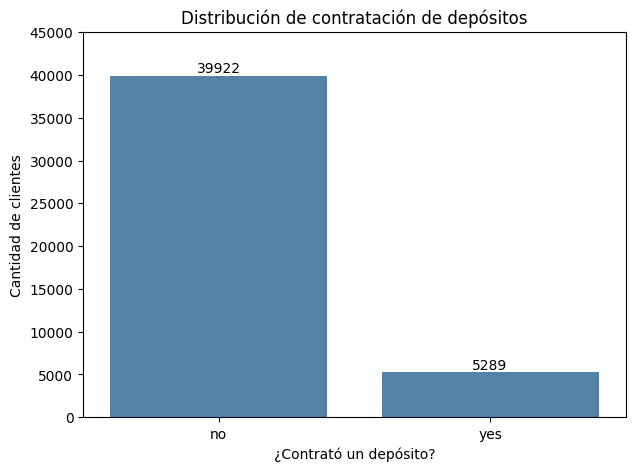

In [4]:
# Conteo de la variable objetivo
conteo = df["y"].value_counts()

print("Distribución de la variable objetivo:")
print(conteo)

# Porcentajes
print("\nDistribución porcentual:")
print((df["y"].value_counts(normalize=True) * 100).round(2))

# Gráfico de distribución
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="y",
    order=["no", "yes"],
    color="steelblue"
)

# Mostrar cantidad sobre cada barra
for barra in ax.patches:
    altura = int(barra.get_height())
    ax.annotate(
        str(altura),
        (barra.get_x() + barra.get_width() / 2, altura),
        ha="center",
        va="bottom"
    )

plt.title("Distribución de contratación de depósitos")
plt.xlabel("¿Contrató un depósito?")
plt.ylabel("Cantidad de clientes")
plt.ylim(0, 45000)
plt.show()

**Interpretación de la variable objetivo:**

El análisis muestra que el 88,3 % de los clientes no contrató un depósito bancario, mientras que solamente el 11,7 % realizó la contratación.

Esto evidencia un desbalance entre las clases de la variable objetivo.

Esta situación deberá considerarse durante el modelamiento y la evaluación, ya que utilizar únicamente Accuracy podría generar una interpretación engañosa del rendimiento.

Por ello, será importante considerar métricas adicionales, como Precision, Recall y F1-score, para evaluar correctamente la capacidad de identificar clientes interesados.

### 2.5 Análisis estadístico descriptivo

Se realizará un análisis estadístico de las variables numéricas del dataset.

Se examinarán medidas como la media, desviación estándar, valores mínimos, máximos y cuartiles.

Esto permitirá comprender la distribución de los datos e identificar posibles valores extremos que requieran revisión durante la preparación.

In [5]:
# Estadísticas descriptivas de las variables numéricas
estadisticas = df.describe().T

# Mostrar resultados
estadisticas

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


**Interpretación estadística:**

Los clientes presentan una edad promedio aproximada de 41 años, con valores entre 18 y 95 años.

El saldo bancario promedio es de 1.362,27 euros, aunque existen valores negativos y saldos considerablemente elevados.

La duración promedio del último contacto es de aproximadamente 258 segundos, mientras que la cantidad promedio de contactos durante la campaña es de 2,76.

En la variable `pdays`, el valor -1 indica que el cliente no fue contactado en campañas anteriores, por lo que no debe considerarse automáticamente como un error.

Se identifican posibles valores extremos en variables como `balance`, `duration`, `campaign` y `previous`, que serán examinados antes de decidir si necesitan tratamiento.

### 2.6 Visualización de variables numéricas

Se utilizarán histogramas para analizar la distribución de las variables `age`, `balance`, `duration` y `campaign`.

Estos gráficos permitirán identificar concentraciones de datos, asimetrías y posibles valores extremos.

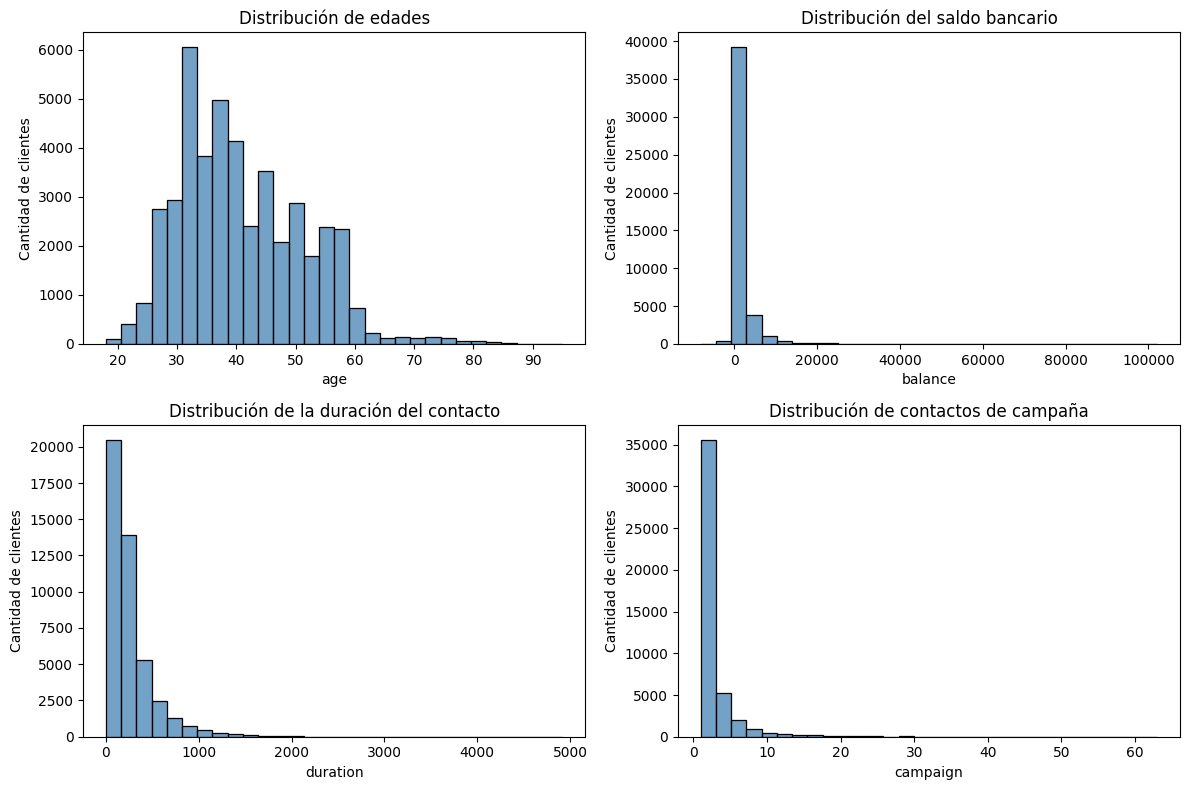

In [6]:
# Variables numéricas que analizaremos
variables = ["age", "balance", "duration", "campaign"]

titulos = [
    "Distribución de edades",
    "Distribución del saldo bancario",
    "Distribución de la duración del contacto",
    "Distribución de contactos de campaña"
]

# Crear cuatro histogramas
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, variable, titulo in zip(axes.flat, variables, titulos):
    sns.histplot(
        data=df,
        x=variable,
        bins=30,
        color="steelblue",
        ax=ax
    )

    ax.set_title(titulo)
    ax.set_xlabel(variable)
    ax.set_ylabel("Cantidad de clientes")

plt.tight_layout()
plt.show()

**Interpretación de las distribuciones numéricas:**

Los histogramas muestran que la mayor concentración de clientes tiene edades comprendidas aproximadamente entre los 30 y 50 años.

La variable `balance` presenta una distribución asimétrica hacia la derecha, debido a la existencia de clientes con saldos bancarios considerablemente elevados.

La duración de los contactos se concentra principalmente en valores bajos, aunque existen llamadas mucho más prolongadas.

Asimismo, la mayoría de los clientes registra pocos contactos durante la campaña, mientras que una proporción reducida presenta cantidades mayores.

Estas distribuciones evidencian posibles valores extremos que deberán evaluarse durante la preparación de los datos, sin eliminarlos automáticamente.

### 2.7 Análisis de variables categóricas

Se analizará la distribución de las variables categóricas `job`, `education`, `housing` y `loan`.

El objetivo es conocer las características más frecuentes entre los clientes y comprender la composición del dataset.

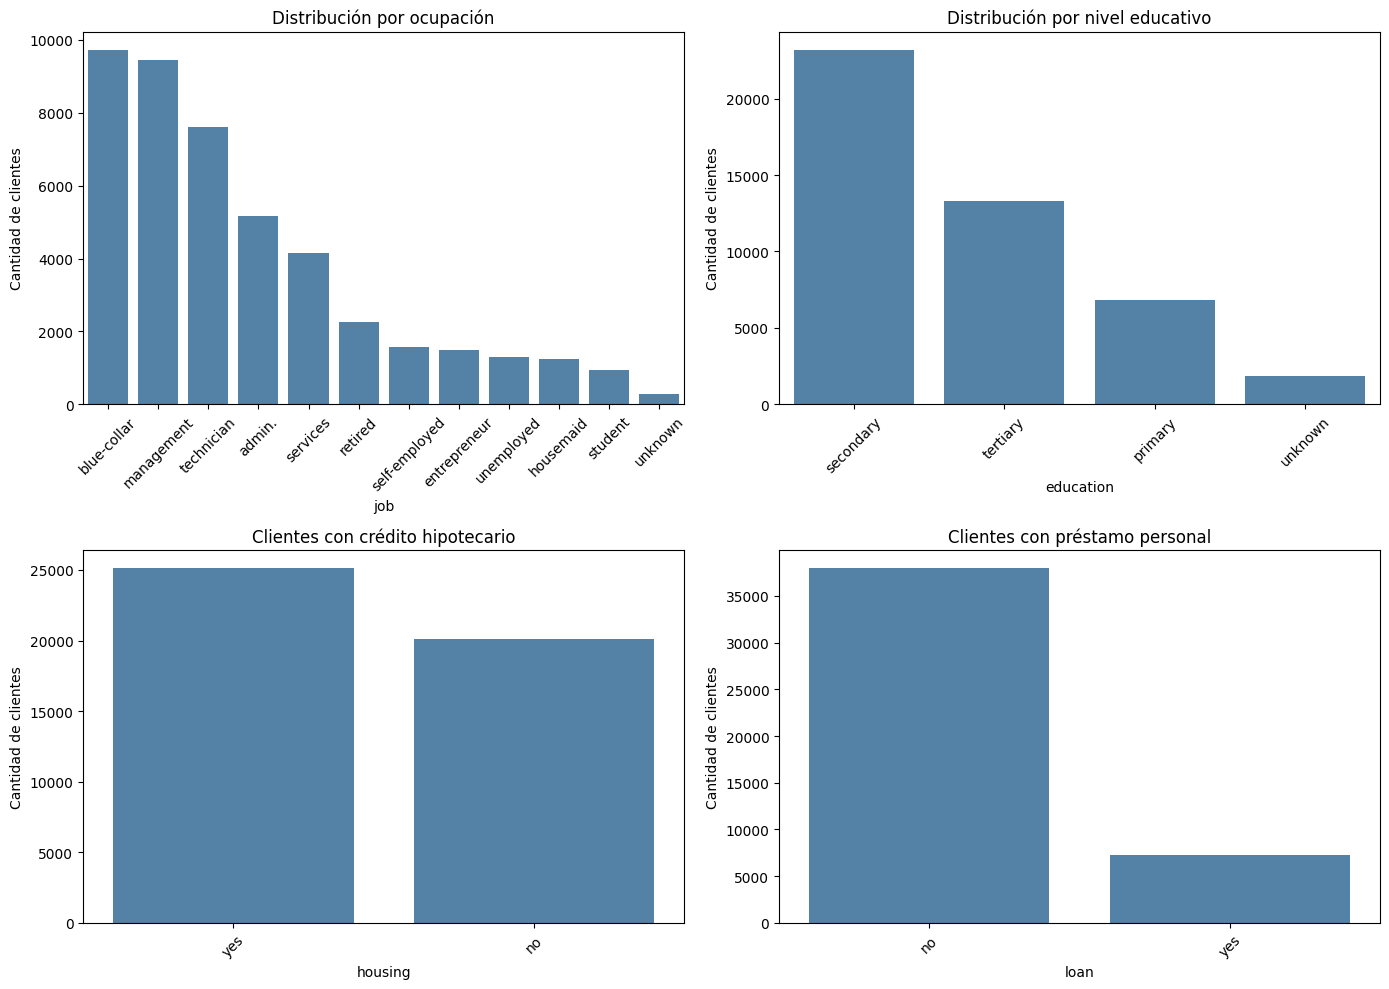

In [7]:
# Variables categóricas que analizaremos
variables_cat = ["job", "education", "housing", "loan"]

titulos = [
    "Distribución por ocupación",
    "Distribución por nivel educativo",
    "Clientes con crédito hipotecario",
    "Clientes con préstamo personal"
]

# Crear cuatro gráficos
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, variable, titulo in zip(axes.flat, variables_cat, titulos):
    orden = df[variable].value_counts().index

    sns.countplot(
        data=df,
        x=variable,
        order=orden,
        color="steelblue",
        ax=ax
    )

    ax.set_title(titulo)
    ax.set_xlabel(variable)
    ax.set_ylabel("Cantidad de clientes")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Interpretación de las variables categóricas:**

El análisis muestra que las ocupaciones más frecuentes corresponden a trabajadores manuales (`blue-collar`), profesionales de gestión (`management`) y técnicos (`technician`).

Respecto al nivel educativo, predomina la educación secundaria, seguida de la educación terciaria y primaria.

En cuanto a la situación financiera, se observa que una proporción ligeramente mayor de clientes posee crédito hipotecario, mientras que la mayoría no mantiene préstamos personales.

Estos resultados permiten comprender la composición de la población bancaria, aunque todavía no permiten determinar qué variables tienen mayor relación con la contratación de depósitos.

### 2.8 Relación de las variables categóricas con la contratación

Se analizará el porcentaje de contratación de depósitos bancarios según la ocupación, nivel educativo, crédito hipotecario y préstamo personal.

Este análisis permitirá identificar posibles relaciones entre las características de los clientes y la variable objetivo `y`.

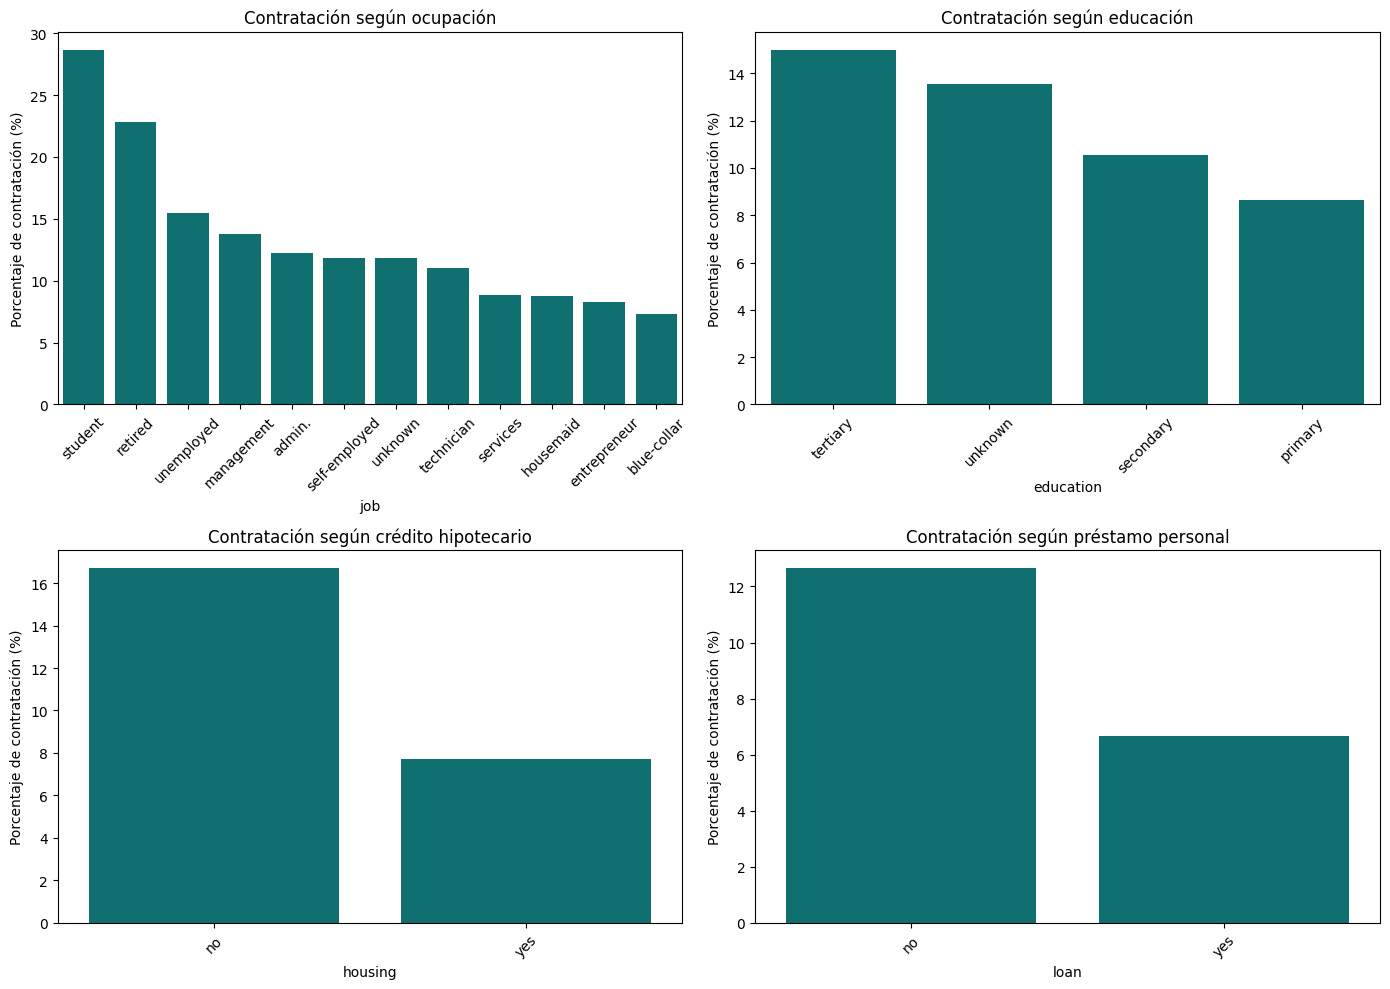

In [8]:
# Variables categóricas que compararemos con la contratación
variables = ["job", "education", "housing", "loan"]

titulos = [
    "Contratación según ocupación",
    "Contratación según educación",
    "Contratación según crédito hipotecario",
    "Contratación según préstamo personal"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, variable, titulo in zip(axes.flat, variables, titulos):

    # Calcular el porcentaje de clientes que contrataron
    tasas = (
        df.groupby(variable)["y"]
        .apply(lambda x: (x == "yes").mean() * 100)
        .sort_values(ascending=False)
    )

    # Crear gráfico
    sns.barplot(
        x=tasas.index,
        y=tasas.values,
        color="teal",
        ax=ax
    )

    ax.set_title(titulo)
    ax.set_xlabel(variable)
    ax.set_ylabel("Porcentaje de contratación (%)")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Interpretación de las tasas de contratación:**

El análisis evidencia diferencias en las tasas de contratación según las características de los clientes.

Los estudiantes y jubilados presentan mayores porcentajes de contratación, mientras que los trabajadores manuales muestran una de las tasas más bajas.

Los clientes con educación terciaria presentan una mayor proporción de contratación que aquellos con educación secundaria o primaria.

Además, se observa que los clientes sin crédito hipotecario y sin préstamo personal tienen mayores tasas de contratación.

Estos resultados sugieren posibles asociaciones entre las características sociodemográficas y financieras de los clientes y su decisión de contratar un depósito bancario.

Sin embargo, será necesario evaluar estas variables durante el modelamiento para determinar su verdadera utilidad predictiva.

### 2.9 Análisis de variables relacionadas con campañas

Se analizarán las variables `poutcome` y `contact` para identificar su relación con la contratación de depósitos bancarios.

Se calculará la cantidad de clientes y el porcentaje de contratación para cada categoría.

In [9]:
# Analizar variables relacionadas con campañas
variables_campana = ["poutcome", "contact"]

for variable in variables_campana:

    print(f"\nANÁLISIS DE {variable.upper()}")

    # Cantidad de clientes según contratación
    tabla = pd.crosstab(df[variable], df["y"])

    # Calcular porcentaje de contratación
    tabla["tasa_contratacion_%"] = (
        tabla["yes"] / tabla[["no", "yes"]].sum(axis=1) * 100
    ).round(2)

    # Ordenar por tasa de contratación
    tabla = tabla.sort_values(
        "tasa_contratacion_%",
        ascending=False
    )

    display(tabla)


ANÁLISIS DE POUTCOME


y,no,yes,tasa_contratacion_%
poutcome,,,
success,533,978,64.73
other,1533,307,16.68
failure,4283,618,12.61
unknown,33573,3386,9.16



ANÁLISIS DE CONTACT


y,no,yes,tasa_contratacion_%
contact,,,
cellular,24916,4369,14.92
telephone,2516,390,13.42
unknown,12490,530,4.07


## Fase 3: Preparación de los datos

### 3.1 Selección de variables y división del dataset

Se separará la variable objetivo `y` de las variables predictoras.

Se excluirá `duration`, debido a que representa la duración del último contacto y no estaría disponible antes de realizar una llamada a un cliente.

Posteriormente, el dataset se dividirá en un 80 % para entrenamiento y un 20 % para prueba.

Se utilizará una división estratificada para mantener proporciones similares de las clases `yes` y `no` en ambos conjuntos.

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Separar X (sin 'duration') e y
X = df.drop(columns=["y", "duration"])
y = df["y"].map({"no": 0, "yes": 1})  # Binarizar variable objetivo (0 = no, 1 = yes)

# 2. Convertir variables categóricas a numéricas (One-Hot Encoding)
X_encoded = pd.get_dummies(X, drop_first=True)

# 3. Dividir los datos: 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

# Mostrar dimensiones
print("DATOS DE ENTRENAMIENTO:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nDATOS DE PRUEBA:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# Verificar distribución de clases (%)
print("\nDISTRIBUCIÓN EN ENTRENAMIENTO (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nDISTRIBUCIÓN EN PRUEBA (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

DATOS DE ENTRENAMIENTO:
X_train: (36168, 41)
y_train: (36168,)

DATOS DE PRUEBA:
X_test: (9043, 41)
y_test: (9043,)

DISTRIBUCIÓN EN ENTRENAMIENTO (%):
y
0    88.3
1    11.7
Name: proportion, dtype: float64

DISTRIBUCIÓN EN PRUEBA (%):
y
0    88.3
1    11.7
Name: proportion, dtype: float64


**Interpretación de la división de datos:**

El dataset fue dividido en 36.168 registros de entrenamiento (80 %) y 9.043 registros de prueba (20 %).

Se conservaron 15 variables predictoras, excluyendo `duration` para evitar utilizar información que no estaría disponible antes de contactar al cliente.

La división estratificada permitió mantener las proporciones originales de la variable objetivo en ambos conjuntos: 88,3 % para `no` y 11,7 % para `yes`.

Esto permitirá evaluar los modelos utilizando datos que no participaron en su entrenamiento.

### 3.2 Preparación de variables numéricas y categóricas

Se identificarán las variables numéricas y categóricas para aplicar las transformaciones necesarias durante el entrenamiento.

Las variables numéricas serán escaladas mediante `StandardScaler`, mientras que las categóricas serán codificadas utilizando `OneHotEncoder`.

Los valores `unknown` se conservarán inicialmente como categorías, ya que podrían contener información relevante.

Se utilizará un `ColumnTransformer` para organizar el preprocesamiento, que posteriormente se integrará en los modelos mediante un Pipeline.

Las transformaciones se ajustarán exclusivamente con los datos de entrenamiento para evitar filtraciones de información.

In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Separar X e y desde el DataFrame original
X = df.drop(columns=["y", "duration"])
y = df["y"].map({"no": 0, "yes": 1})  # Convertir 'no' -> 0 y 'yes' -> 1

# 2. Dividir manteniendo las 15 columnas originales
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Identificar variables numéricas y categóricas
columnas_numericas = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
columnas_categoricas = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

# 4. Crear el preprocesador
preprocesador = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), columnas_numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), columnas_categoricas),
    ]
)

# 5. Transformar X_train y X_test (PASO CLAVE PARA LA SIGUIENTE FASE)
X_train_processed = preprocesador.fit_transform(X_train)
X_test_processed = preprocesador.transform(X_test)

print("VARIABLES NUMÉRICAS (6):", columnas_numericas)
print("VARIABLES CATEGÓRICAS (9):", columnas_categoricas)
print("PREPROCESADOR CREADO Y DATOS TRANSFORMADOS CORRECTAMENTE")
print("Forma de X_train_processed:", X_train_processed.shape)

VARIABLES NUMÉRICAS (6): ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
VARIABLES CATEGÓRICAS (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
PREPROCESADOR CREADO Y DATOS TRANSFORMADOS CORRECTAMENTE
Forma de X_train_processed: (36168, 41)


C:\Users\aguir\AppData\Local\Temp\ipykernel_18028\2004516341.py:17: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_categoricas = X_train.select_dtypes(include=["object", "category"]).columns.tolist()


### 3.3 Decisiones de preparación de datos

Durante la preparación del dataset se tomaron las siguientes decisiones:

- Se verificó que no existen valores nulos ni registros duplicados.
- Se conservaron inicialmente las categorías `unknown`, ya que pueden representar información relevante.
- Se mantuvo el valor -1 de `pdays`, porque indica que el cliente no fue contactado anteriormente.
- No se eliminaron automáticamente los valores extremos, dado que pueden corresponder a registros válidos.
- Se excluyó `duration` para evitar utilizar información desconocida antes de contactar al cliente.
- Se dividió el dataset en 80 % de entrenamiento y 20 % de prueba mediante una separación estratificada.
- Se definió un preprocesador con `StandardScaler` para variables numéricas y `OneHotEncoder` para categóricas.

El preprocesador se integrará posteriormente con los algoritmos de clasificación mediante un Pipeline, ajustándose exclusivamente con datos de entrenamiento.


In [12]:
#  Ajustar y transformar X_train usando el preprocesador
X_train_procesado = preprocesador.fit_transform(X_train)

#  Obtener los nombres de las nuevas columnas generadas (numéricas + One-Hot)
nombres_columnas_transformadas = preprocesador.get_feature_names_out()

# Imprimir el resultado de la verificación
print(
    f" Columnas originales en X_train: {X_train.shape[1]}"
)
print(
    f" Columnas procesadas tras One-Hot Encoding: {X_train_procesado.shape[1]}"
)
print("\nPrimeras 10 columnas transformadas:")
print(nombres_columnas_transformadas[:10])

 Columnas originales en X_train: 15
 Columnas procesadas tras One-Hot Encoding: 41

Primeras 10 columnas transformadas:
['num__age' 'num__balance' 'num__day' 'num__campaign' 'num__pdays'
 'num__previous' 'cat__job_blue-collar' 'cat__job_entrepreneur'
 'cat__job_housemaid' 'cat__job_management']


In [13]:
# Verificaciones finales para el modelamiento

assert X_train.shape[1] == 15
assert X_train.columns.equals(X_test.columns)
assert len(columnas_numericas) == 6
assert len(columnas_categoricas) == 9
assert X_train.isnull().sum().sum() == 0
assert X_test.isnull().sum().sum() == 0

print("VERIFICACIÓN FINAL")
print("Variables predictoras:", X_train.shape[1])
print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))
print("Variables numéricas:", len(columnas_numericas))
print("Variables categóricas:", len(columnas_categoricas))

print("\nDatos preparados correctamente para el modelamiento.")

VERIFICACIÓN FINAL
Variables predictoras: 15
Registros de entrenamiento: 36168
Registros de prueba: 9043
Variables numéricas: 6
Variables categóricas: 9

Datos preparados correctamente para el modelamiento.


# Fase 4: Modelamiento

En esta fase se entrenan y evalúan los modelos de Árbol de Decisión , Regresión Logística y Random Forest. Ambos comparten el mismo objeto preprocesador (ColumnTransformer) dentro de sus respectivos Pipeline para garantizar un preprocesamiento uniforme sin fuga de datos (data leakage).

In [14]:
from sklearn.pipeline import Pipeline

def crear_pipeline(modelo):
    """Retorna un Pipeline con el preprocesador ya definido y el modelo solicitado."""
    return Pipeline([
        ("prep", preprocesador),
        ("modelo", modelo)
    ])

### 4.1 Árbol de Decisión (Decision Tree)
Se entrena un modelo base de Árbol de Decisión utilizando el pipeline de preprocesamiento sobre los datos de entrenamiento. Posteriormente, se realiza una búsqueda de hiperparámetros mediante `GridSearchCV` para optimizar la métrica F1-Score y mitigar el sobreajuste.

In [15]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Crear y entrenar el modelo base usando la función reutilizable
modelo_base_clf = crear_pipeline(DecisionTreeClassifier(random_state=42))

modelo_base_clf.fit(X_train, y_train)
pred_base_clf = modelo_base_clf.predict(X_test)

# Métricas
f1_base = f1_score(y_test, pred_base_clf)
acc_base = accuracy_score(y_test, pred_base_clf)

print("Accuracy modelo base:", round(acc_base, 4))
print("F1 modelo base      :", round(f1_base, 4))
print()
print(classification_report(y_test, pred_base_clf))

Accuracy modelo base: 0.8304
F1 modelo base      : 0.3133

              precision    recall  f1-score   support

           0       0.91      0.90      0.90      7985
           1       0.30      0.33      0.31      1058

    accuracy                           0.83      9043
   macro avg       0.60      0.61      0.61      9043
weighted avg       0.84      0.83      0.83      9043



In [16]:
import time
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

# GridSearchCV para Árbol de Decisión usando la función
param_grid = {
    "modelo__max_depth": [3, 5, 8, 12, None],
    "modelo__min_samples_split": [2, 5, 10],
    "modelo__min_samples_leaf": [1, 2, 5],
    "modelo__class_weight": [None, "balanced"]
}

grid_search = GridSearchCV(
    estimator=crear_pipeline(DecisionTreeClassifier(random_state=42)),
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    return_train_score=True
)

inicio = time.time()
grid_search.fit(X_train, y_train)
tiempo_grid = time.time() - inicio

print("Mejores hiperparámetros:")
print(grid_search.best_params_)

print("\nMejor F1 promedio en CV:")
print(round(grid_search.best_score_, 4))

print("\nTiempo GridSearchCV:")
print(round(tiempo_grid, 2), "segundos")

Mejores hiperparámetros:
{'modelo__class_weight': 'balanced', 'modelo__max_depth': 8, 'modelo__min_samples_leaf': 1, 'modelo__min_samples_split': 10}

Mejor F1 promedio en CV:
0.4228

Tiempo GridSearchCV:
148.13 segundos


In [17]:
# Evaluar mejor árbol en test

mejor_arbol = grid_search.best_estimator_
pred_grid = mejor_arbol.predict(X_test)

f1_grid = f1_score(y_test, pred_grid)
acc_grid = accuracy_score(y_test, pred_grid)

print("Accuracy optimizado:", round(acc_grid, 4))
print("F1 optimizado      :", round(f1_grid, 4))
print()
print(classification_report(y_test, pred_grid))

Accuracy optimizado: 0.8325
F1 optimizado      : 0.4383

              precision    recall  f1-score   support

           0       0.94      0.87      0.90      7985
           1       0.36      0.56      0.44      1058

    accuracy                           0.83      9043
   macro avg       0.65      0.71      0.67      9043
weighted avg       0.87      0.83      0.85      9043



,Modelo,Accuracy,F1
0,Árbol Base,0.8304,0.3133
1,Árbol Optimizado,0.8325,0.4383


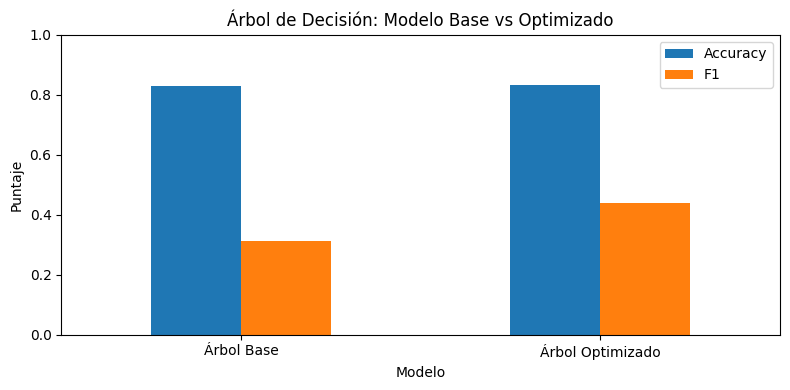

In [18]:
# Comparación visual: Árbol de Decisión Base vs GridSearchCV

comparacion_dt = pd.DataFrame({
    "Modelo": ["Árbol Base", "Árbol Optimizado"],
    "Accuracy": [acc_base, acc_grid],
    "F1": [f1_base, f1_grid]
})

display(comparacion_dt.round(4))

comparacion_dt.set_index("Modelo")[["Accuracy", "F1"]].plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("Árbol de Decisión: Modelo Base vs Optimizado")
plt.ylabel("Puntaje")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 4.2 Regresión Logística (Logistic Regression)
Se evalúa un algoritmo lineal como punto de comparación. La Regresión Logística permite modelar la probabilidad de la variable objetivo binaria. Se entrena primero el modelo base y luego se ajusta mediante `GridSearchCV` evaluando la penalización y el parámetro de regularización $C$.

In [19]:
from sklearn.linear_model import LogisticRegression

#  Regresión Logística Base
modelo_base_lr = crear_pipeline(LogisticRegression(random_state=42, max_iter=1000))
modelo_base_lr.fit(X_train, y_train)
pred_base_lr = modelo_base_lr.predict(X_test)

f1_base_lr = f1_score(y_test, pred_base_lr)
acc_base_lr = accuracy_score(y_test, pred_base_lr)

print("Accuracy modelo base (LR):", round(acc_base_lr, 4))
print("F1 modelo base (LR)      :", round(f1_base_lr, 4))
print()
print(classification_report(y_test, pred_base_lr))

Accuracy modelo base (LR): 0.8933
F1 modelo base (LR)      : 0.2793

              precision    recall  f1-score   support

           0       0.90      0.99      0.94      7985
           1       0.67      0.18      0.28      1058

    accuracy                           0.89      9043
   macro avg       0.78      0.58      0.61      9043
weighted avg       0.87      0.89      0.86      9043



In [20]:
import time
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

# Definir la malla de parámetros para Regresión Logística
param_grid_lr = {
    "modelo__C": [0.01, 0.1, 1.0, 10.0],
    "modelo__solver": ["lbfgs", "saga"],
    "modelo__class_weight": [None, "balanced"]
}

# Configurar GridSearchCV usando la función reutilizable
grid_search_lr = GridSearchCV(
    estimator=crear_pipeline(LogisticRegression(random_state=42, max_iter=1000)),
    param_grid=param_grid_lr,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    return_train_score=True
)

# Entrenar y medir tiempo
inicio = time.time()
grid_search_lr.fit(X_train, y_train)
tiempo_grid_lr = time.time() - inicio

print("Mejores hiperparámetros (LR):")
print(grid_search_lr.best_params_)

print("\nMejor F1 promedio en CV (LR):")
print(round(grid_search_lr.best_score_, 4))

print("\nTiempo GridSearchCV (LR):")
print(round(tiempo_grid_lr, 2), "segundos")

Mejores hiperparámetros (LR):
{'modelo__C': 1.0, 'modelo__class_weight': 'balanced', 'modelo__solver': 'saga'}

Mejor F1 promedio en CV (LR):
0.3754

Tiempo GridSearchCV (LR):
116.75 segundos


In [21]:
# Evaluar la mejor Regresión Logística en el conjunto de prueba
mejor_lr = grid_search_lr.best_estimator_
pred_grid_lr = mejor_lr.predict(X_test)

f1_grid_lr = f1_score(y_test, pred_grid_lr)
acc_grid_lr = accuracy_score(y_test, pred_grid_lr)

print("Accuracy optimizado (LR):", round(acc_grid_lr, 4))
print("F1 optimizado (LR)      :", round(f1_grid_lr, 4))
print()
print(classification_report(y_test, pred_grid_lr))

Accuracy optimizado (LR): 0.7588
F1 optimizado (LR)      : 0.3767

              precision    recall  f1-score   support

           0       0.94      0.78      0.85      7985
           1       0.27      0.62      0.38      1058

    accuracy                           0.76      9043
   macro avg       0.60      0.70      0.61      9043
weighted avg       0.86      0.76      0.80      9043



,Modelo,Accuracy,F1
0,Reg. Logística Base,0.8933,0.2793
1,Reg. Logística Optimizada,0.7588,0.3767


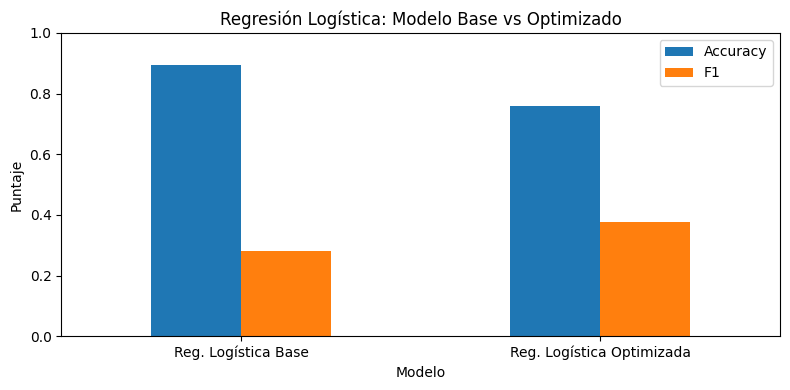

In [22]:
# Comparación visual: Regresión Logística Base vs GridSearchCV

comparacion_lr = pd.DataFrame({
    "Modelo": ["Reg. Logística Base", "Reg. Logística Optimizada"],
    "Accuracy": [acc_base_lr, acc_grid_lr],
    "F1": [f1_base_lr, f1_grid_lr]
})

display(comparacion_lr.round(4))

comparacion_lr.set_index("Modelo")[["Accuracy", "F1"]].plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("Regresión Logística: Modelo Base vs Optimizado")
plt.ylabel("Puntaje")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 4.3 Random Forest
Se evalúa un ensamble de árboles de decisión (Random Forest) para mejorar la capacidad de generalización y reducir la varianza. Se entrena primero el modelo base y luego se realiza una búsqueda exhaustiva con `GridSearchCV` para optimizar el número de estimadores (`n_estimators`), la profundidad máxima (`max_depth`) y el balance de pesos (`class_weight`).

In [23]:
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

#  Modelo Base (Random Forest)
modelo_base_rf = crear_pipeline(RandomForestClassifier(random_state=42))
modelo_base_rf.fit(X_train, y_train)
pred_base_rf = modelo_base_rf.predict(X_test)

f1_base_rf = f1_score(y_test, pred_base_rf)
acc_base_rf = accuracy_score(y_test, pred_base_rf)

print("--- Random Forest (Modelo Base) ---")
print("Accuracy modelo base (RF):", round(acc_base_rf, 4))
print("F1 modelo base (RF)      :", round(f1_base_rf, 4))
print()
print(classification_report(y_test, pred_base_rf))



--- Random Forest (Modelo Base) ---
Accuracy modelo base (RF): 0.8944
F1 modelo base (RF)      : 0.3336

              precision    recall  f1-score   support

           0       0.91      0.98      0.94      7985
           1       0.64      0.23      0.33      1058

    accuracy                           0.89      9043
   macro avg       0.77      0.60      0.64      9043
weighted avg       0.87      0.89      0.87      9043



In [24]:
#  GridSearchCV para Random Forest
param_grid_rf = {
    "modelo__n_estimators": [50, 100, 200],
    "modelo__max_depth": [5, 10, None],
    "modelo__min_samples_split": [2, 5],
    "modelo__class_weight": [None, "balanced"]
}

grid_search_rf = GridSearchCV(
    estimator=crear_pipeline(RandomForestClassifier(random_state=42)),
    param_grid=param_grid_rf,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    return_train_score=True
)

inicio = time.time()
grid_search_rf.fit(X_train, y_train)
tiempo_grid_rf = time.time() - inicio

print("\n--- Random Forest (GridSearchCV) ---")
print("Mejores hiperparámetros (RF):")
print(grid_search_rf.best_params_)

print("\nMejor F1 promedio en CV (RF):")
print(round(grid_search_rf.best_score_, 4))

print("\nTiempo GridSearchCV (RF):")
print(round(tiempo_grid_rf, 2), "segundos")




--- Random Forest (GridSearchCV) ---
Mejores hiperparámetros (RF):
{'modelo__class_weight': 'balanced', 'modelo__max_depth': 10, 'modelo__min_samples_split': 5, 'modelo__n_estimators': 100}

Mejor F1 promedio en CV (RF):
0.4396

Tiempo GridSearchCV (RF):
994.05 segundos


In [25]:
# Evaluación del modelo optimizado en Test
mejor_rf = grid_search_rf.best_estimator_
pred_grid_rf = mejor_rf.predict(X_test)

f1_grid_rf = f1_score(y_test, pred_grid_rf)
acc_grid_rf = accuracy_score(y_test, pred_grid_rf)

print("\n--- Random Forest (Modelo Optimizado) ---")
print("Accuracy optimizado (RF):", round(acc_grid_rf, 4))
print("F1 optimizado (RF)      :", round(f1_grid_rf, 4))
print()
print(classification_report(y_test, pred_grid_rf))


--- Random Forest (Modelo Optimizado) ---
Accuracy optimizado (RF): 0.8227
F1 optimizado (RF)      : 0.4451

              precision    recall  f1-score   support

           0       0.94      0.85      0.89      7985
           1       0.35      0.61      0.45      1058

    accuracy                           0.82      9043
   macro avg       0.65      0.73      0.67      9043
weighted avg       0.87      0.82      0.84      9043



,Modelo,Accuracy,F1
0,Random Forest Base,0.8944,0.3336
1,Random Forest Optimizado,0.8227,0.4451


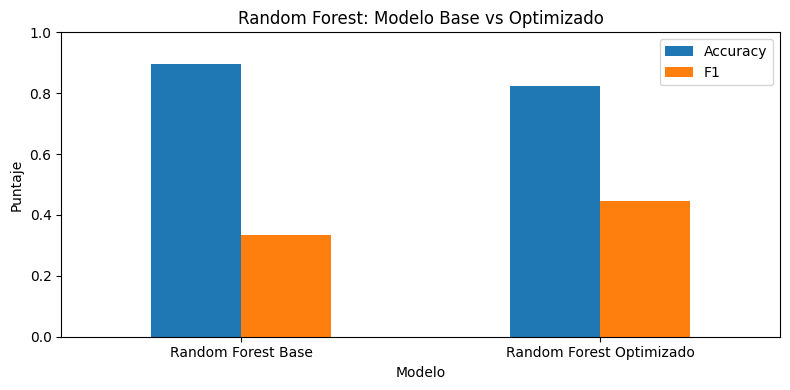

In [26]:
# Comparación visual: Random Forest Base vs GridSearchCV

comparacion_rf = pd.DataFrame({
    "Modelo": ["Random Forest Base", "Random Forest Optimizado"],
    "Accuracy": [acc_base_rf, acc_grid_rf],
    "F1": [f1_base_rf, f1_grid_rf]
})

display(comparacion_rf.round(4))

comparacion_rf.set_index("Modelo")[["Accuracy", "F1"]].plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("Random Forest: Modelo Base vs Optimizado")
plt.ylabel("Puntaje")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

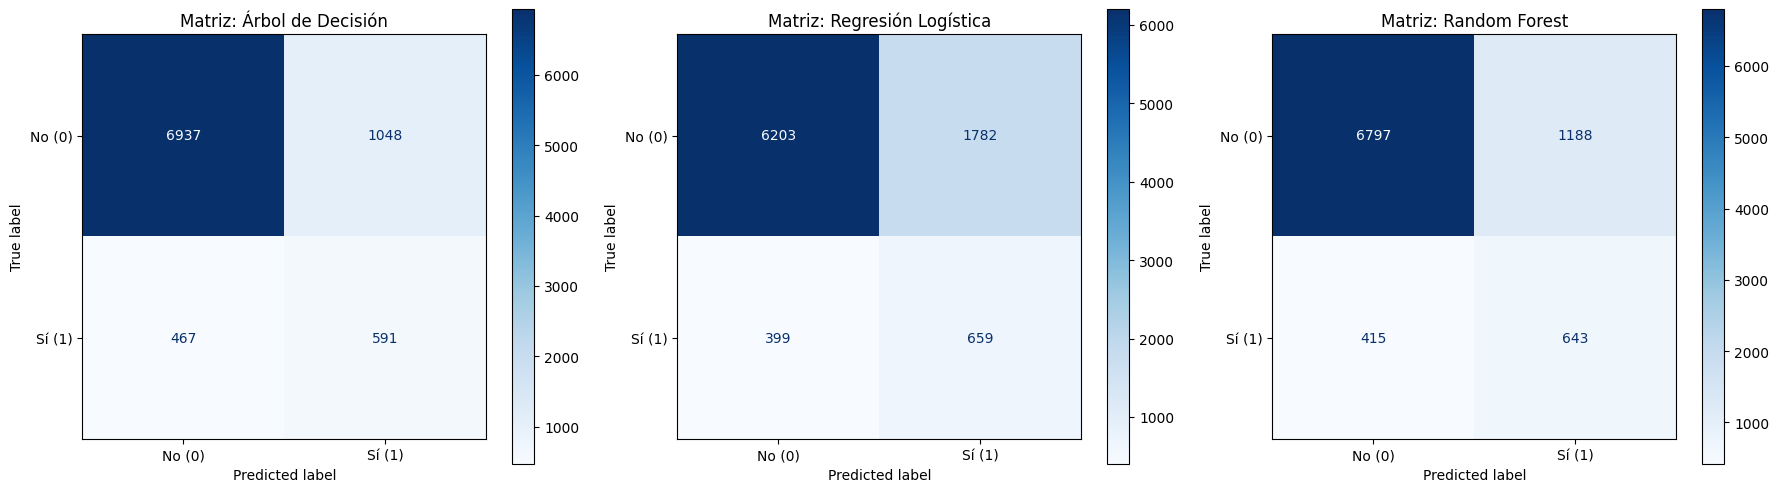

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Crear subplots para las matrices de confusión
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

modelos_opt = [
    ("Árbol de Decisión", mejor_arbol, axes[0]),
    ("Regresión Logística", mejor_lr, axes[1]),
    ("Random Forest", mejor_rf, axes[2])
]

# Lista para almacenar el desglose de métricas por modelo
desglose_cm = []

for nombre, modelo, ax in modelos_opt:
    pred = modelo.predict(X_test)
    cm = confusion_matrix(y_test, pred)

    # Graficar la matriz
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No (0)", "Sí (1)"])
    disp.plot(ax=ax, cmap="Blues", values_format="d")
    ax.set_title(f"Matriz: {nombre}")

    # Extraer VN, FP, FN, VP
    # .ravel() aplana la matriz 2x2 en [VN, FP, FN, VP]
    vn, fp, fn, vp = cm.ravel()
    total = vn + fp + fn + vp

    desglose_cm.append({
        "Modelo": nombre,
        "Verdaderos Negativos (VN)": vn,
        "Falsos Positivos (FP)": fp,
        "Falsos Negativos (FN)": fn,
        "Verdaderos Positivos (VP)": vp,
        "Tasa Falsos Positivos (FPR)": f"{(fp / (fp + vn)):.2%}",
        "Tasa Falsos Negativos (FNR)": f"{(fn / (fn + vp)):.2%}"
    })

plt.tight_layout()
plt.show()



In [28]:
# 2. Crear y mostrar la tabla comparativa
df_cm = pd.DataFrame(desglose_cm)
display(df_cm)

,Modelo,Verdaderos Negativos (VN),Falsos Positivos (FP),Falsos Negativos (FN),Verdaderos Positivos (VP),Tasa Falsos Positivos (FPR),Tasa Falsos Negativos (FNR)
0,Árbol de Decisión,6937,1048,467,591,13.12%,44.14%
1,Regresión Logística,6203,1782,399,659,22.32%,37.71%
2,Random Forest,6797,1188,415,643,14.88%,39.22%


# Fase 5: Evaluación

En esta fase se evalúan rigurosamente los modelos ajustados en la fase anterior para determinar cuál responde de manera óptima a las necesidades y objetivos del negocio. Dado que la variable objetivo (`y`: contratación de un depósito a plazo) presenta un **severo desbalance de clases** (88.3% "no" vs. 11.7% "yes"), la evaluación no se enfoca únicamente en el *Accuracy*, sino en métricas orientadas a la detección efectiva de la clase minoritaria.

## 5.1 Contexto y Consideraciones sobre el Desbalance de Clases

Evaluamos los tres algoritmos optimizados (**Árbol de Decisión**, **Regresión Logística** y **Random Forest**) sobre el conjunto de prueba independiente ($N = 9043$).

En un escenario desbalanceado, un modelo ingenuo que prediga siempre la clase mayoritaria ("no") obtendría un *Accuracy* del **88.3%**, pero tendría una utilidad nula para el banco. Por ello, se utilizan las siguientes métricas de evaluación centradas en la clase de interés (clase 1 = "yes"):

* **F1-Score (clase 1):** Métrica principal de optimización que representa la media armónica entre Precision y Recall.
* **Recall / Sensibilidad (clase 1):** Porcentaje de clientes realmente interesados que el modelo logra identificar.
* **Precision (clase 1):** Porcentaje de aciertos cuando el modelo predice que un cliente contratará.
* **Tasa de Falsos Negativos (FNR):** Porcentaje de clientes potenciales perdidos (costo de oportunidad).
* **Tasa de Falsos Positivos (FPR):** Porcentaje de contactos inútiles hacia clientes no interesados (costo operativo).

## 5.2 Resumen de Resultados de los Modelos Optimizados

La siguiente tabla resume el desempeño obtenido por cada modelo en el conjunto de prueba tras la optimización de hiperparámetros con `GridSearchCV` y el ajuste de pesos de clase (`class_weight='balanced'`):

| Modelo | Accuracy | F1-Score (Clase 1) | Recall (Clase 1) | Precision (Clase 1) | VN (0) | FP (0) | FN (1) | VP (1) | FPR (%) | FNR (%) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Árbol de Decisión** | 0.8325 | 0.4383 | 0.56 | 0.36 | 6937 | 1048 | 467 | 591 | 13.12% | 44.14% |
| **Regresión Logística** | 0.7588 | 0.3767 | 0.62 | 0.27 | 6203 | 1782 | 399 | 659 | 22.32% | 37.71% |
| **Random Forest** | **0.8227** | **0.4451** | **0.61** | **0.35** | 6797 | 1188 | 415 | 643 | 14.88% | 39.22% |

## 5.3 Análisis Detallado e Interpretación por Modelo

### 1. Árbol de Decisión Optimizado
* **Hiperparámetros óptimos:** `max_depth: 8`, `min_samples_split: 10`, `class_weight: 'balanced'`.
* **Interpretación del desempeño:**
  * **Evolución respecto al baseline:** El ajuste de hiperparámetros permitió elevar el F1-Score a **0.4383**, superando el rendimiento inicial del modelo sin optimizar.
  * **Fragilidad frente a falsos negativos:** Presenta la tasa de Falsos Negativos más alta del estudio (**FNR: 44.14%**). Esto significa que de cada 100 clientes dispuestos a contratar un depósito, el modelo ignora a 44 de ellos. En la práctica, esto representa **467 oportunidades de venta perdidas**, lo cual reduce severamente su efectividad comercial.
  * **Comportamiento estructural:** Al ser un único árbol con profundidad limitada (`max_depth: 8`), tiende a segmentar el espacio de datos con cortes demasiado rígidos. Aunque logra un *Accuracy* del 83.25%, este número engañoso es inflado por la clase mayoritaria y oculta su baja capacidad para capturar patrones complejos en la clase de interés.

---

### 2. Regresión Logística Optimizada
* **Hiperparámetros óptimos:** `C: 1.0`, `solver: 'saga'`, `class_weight: 'balanced'`.
* **Interpretación del desempeño:**
  * **Sesgo hacia la captura máxima (Alto Recall):** Es el modelo más "agresivo" en la detección de la clase positiva, alcanzando un **Recall del 62%** (659 depósitos capturados). El balanceo de clases forzó al algoritmo a desplazar su umbral de decisión para priorizar no perder clientes interesados.
  * **Penalización en precisión y costo operativo:** Su naturaleza lineal le impide separar de manera limpia las clases cuando hay superposición en los datos. Para lograr capturar esos 659 depósitos, el modelo genera **1,782 Falsos Positivos** (una Tasa de Falsas Alarmas / FPR del 22.32%).
  * **Consecuencia de negocio:** Solo el **27% de las llamadas realizadas serían efectivas** (Precision). El 73% restante de las llamadas se realizaría a clientes sin interés, sobrecargando la operación del *Call Center* y erosionando el margen de beneficio neto de la campaña.

---

### 3. Random Forest Optimizado
* **Hiperparámetros óptimos:** `n_estimators: 100`, `max_depth: 10`, `min_samples_split: 5`, `class_weight: 'balanced'`.
* **Interpretación del desempeño:**
  * **Dominio por ensamble:** Al promediar 100 árboles de decisión (`n_estimators: 100`), reduce significativamente la varianza y el sesgo que afectaban al árbol individual, alcanzando el **F1-Score más alto (0.4451)**.
  * **Punto de equilibrio óptimo:** Logra capturar prácticamente la misma cantidad de clientes interesados que la Regresión Logística (643 vs. 659 depósitos, un **Recall del 61%**), pero **con 594 Falsos Positivos menos** (1,188 frente a 1,782).
  * **Eficiencia operacional:** Mantiene una precisión del **35%**, lo que garantiza que 1 de cada 3 contactos resulte en una venta concreta. Además, reduce la Tasa de Falsos Negativos al 39.22%, ofreciendo el balance comercial más rentable entre captación de capital y optimización de recursos.

## 5.4 Evaluación del Impacto en el Negocio

Al trasladar la matriz de confusión a métricas del negocio bancario, evaluamos el balance entre costo operativo y costo de oportunidad:

1. **Costo de Falso Positivo (FP):** Tiempo del agente y costo de la llamada realizada a un cliente que no está interesado.
2. **Costo de Falso Negativo (FN):** Pérdida de la captación del capital del depósito por no haber contactado al cliente.

* **Comparativa del impacto:**
  * La **Regresión Logística** exigiría realizar **1,782 llamadas infructuosas**.
  * **Random Forest** logra capturar prácticamente la misma cantidad de clientes interesados (643 vs 659), pero **ahorra 594 llamadas innecesarias** frente a la Regresión Logística. Esto maximiza la eficiencia del centro de llamadas (*Call Center*) y reduce la fricción por sobrecontacto con los clientes.

## 5.5 Selección del Modelo Final y Justificación

### **Modelo Seleccionado:** `Random Forest Optimizado`

### **Justificación Técnica y de Negocio:**
1. **Mayor Equilibrio F1-Score:** Logra el valor más alto (0.4451 en prueba vs 0.4396 en CV), demostrando una alta capacidad de generalización sin *overfitting*.
2. **Eficiencia Comercial:** Identifica al **61% de los compradores potenciales** manteniendo una tasa de llamadas infructuosas significativamente menor que otros modelos de alto Recall.
3. **Robustez:** La arquitectura de ensamble basada en árboles gestiona de manera superior las relaciones no lineales y las interacciones complejas entre las características del cliente.

## 5.6 Mejoras Críticas para la Siguiente Iteración

Para incrementar de forma directa el rendimiento comercial del modelo y resolver el desbalance de clases sin complejidades innecesarias, las 3 acciones prioritarias para el próximo ciclo son:

### 1. Ajuste del Umbral de Decisión (*Threshold Tuning*)
* **Por qué es prioritario:** Por defecto, los modelos clasifican a un cliente como "interesado" cuando su probabilidad es mayor al 50% ($p > 0.50$).
* **Mejora concreta:** Mover este umbral (por ejemplo, a $p = 0.30$ o $p = 0.35$). Esto permite capturar muchos más clientes potenciales (**aumentar el Recall**) ajustándose exactamente a la capacidad diaria de llamadas del *Call Center*, sin necesidad de reentrenar ni cambiar de modelo.

### 2. Implementación de XGBoost o LightGBM
* **Por qué es prioritario:** Los algoritmos de *Gradient Boosting* superan sistemáticamente a Random Forest en datos bancarios desbalanceados, ya que construyen árboles de forma secuencial corrigiendo los errores de los árboles anteriores.
* **Mejora concreta:** Entrenar un modelo `LGBMClassifier` o `XGBClassifier` utilizando el parámetro `scale_pos_weight` para penalizar automáticamente los errores en la clase minoritaria, lo que elevará el F1-Score y la precisión del modelo.



# Iteración 2: Volver a la comprensión del negocio y usar solo variables conocidas antes de llamar

## Por qué se vuelve a la Fase 1

CRISP-DM no es una secuencia lineal: al terminar la Fase 5 se revisa si el resultado responde a la pregunta del negocio y, si hay algo que corregir, se vuelve a la fase que corresponda.

Al revisar los resultados de la iteración 1 se retomó la pregunta de la Fase 1: **¿para qué usaría el banco este modelo?** Para decidir a qué clientes llamar y a cuáles no. Eso significa que el modelo debe entregar su predicción **antes de la llamada**, usando solo información que el banco ya tiene en ese momento.

En la iteración 1 ya se había excluido `duration` por este motivo (la duración de una llamada solo se conoce cuando la llamada termina). Sin embargo, el mismo criterio no se aplicó a las demás variables, y hay dos más que tampoco se conocen antes de llamar: `day` y `campaign`.

## Recorrido de esta iteración

| Paso | Fase de CRISP-DM | Qué se hace |
| :--- | :--- | :--- |
| 1 | Fase 1 (revisada) | Se precisa el uso del modelo y se define el criterio: una variable solo se usa si se conoce antes de llamar. |
| 2 | Fase 2 (revisada) | Se examinan las variables dudosas (`day`, `campaign`, `month`, `contact`). |
| 3 | Fase 3 | Se quitan `day` y `campaign`, se mantiene el resto y se mide cuánto aporta cada grupo de variables. |
| 4 | Fase 4 | Se entrenan los mismos tres algoritmos, con las mismas grillas de la iteración 1. |
| 5 | Fase 5 | Se comparan los resultados con la iteración 1 y se decide si el modelo sirve para su uso real. |

Se mantienen la misma división de datos (80 % entrenamiento, 20 % prueba, `random_state=42`), los mismos algoritmos, las mismas grillas de hiperparámetros y la misma métrica principal (F1-score de la clase `yes`). Así, la única diferencia entre ambas iteraciones es el conjunto de variables y cualquier cambio en los resultados se puede atribuir a eso.

## Fase 1 (revisada): Comprensión del negocio

### 1.7 Uso real del modelo y criterio de disponibilidad

El banco quiere usar el modelo para **priorizar a quién llamar** en una campaña. El ejecutivo necesita la predicción antes de marcar el número, de modo que cada variable del modelo debe estar disponible en ese momento.

Se clasificaron las 15 variables de la iteración 1 según ese criterio:

| Grupo | Variables | ¿Se conoce antes de llamar? | Decisión |
| :--- | :--- | :--- | :--- |
| Perfil del cliente | `age`, `job`, `marital`, `education`, `default`, `balance`, `housing`, `loan` | Sí, son datos del cliente que el banco ya tiene. | Se mantienen |
| Historial de campañas anteriores | `pdays`, `previous`, `poutcome` | Sí, corresponden a contactos pasados. | Se mantienen |
| Plan de la campaña | `contact`, `month` | Sí, las decide el banco al planificar (medio de contacto y mes en que se llama). | Se mantienen, con una salvedad (ver 2.11) |
| Registro de las llamadas | `day`, `campaign` | No. Son el resultado de cómo avanzó la campaña: `campaign` cuenta los contactos realizados incluyendo el último, y `day` es el día de ese último contacto. | **Se excluyen** |
| Duración de la llamada | `duration` | No. | Ya excluida en la iteración 1 |

Los criterios de éxito no cambian (Accuracy, Precision, Recall y F1-score). Lo que cambia es la expectativa: **no se espera que el F1 mejore**, porque se está quitando información. Lo que se busca es un modelo cuyas cifras sean honestas, es decir, que se puedan alcanzar cuando se use de verdad antes de llamar.

In [29]:
import numpy as np
import pandas as pd

grupos_variables = {
    "Perfil del cliente": ["age", "job", "marital", "education", "default", "balance", "housing", "loan"],
    "Historial de campañas anteriores": ["pdays", "previous", "poutcome"],
    "Plan de la campaña": ["contact", "month"],
    "Registro de las llamadas": ["day", "campaign"],
}

# Todas las variables de la iteración 1 quedan clasificadas, ninguna repetida
todas = [v for lista in grupos_variables.values() for v in lista]
assert sorted(todas) == sorted(X_train.columns) and len(todas) == len(set(todas)) == 15

variables_excluidas_it2 = grupos_variables["Registro de las llamadas"]

resumen_grupos = pd.DataFrame({
    "Grupo": list(grupos_variables),
    "N.º de variables": [len(v) for v in grupos_variables.values()],
    "Variables": [", ".join(v) for v in grupos_variables.values()],
    "Se usa en la iteración 2": ["Sí", "Sí", "Sí", "No"],
})
display(resumen_grupos)

,Grupo,N.º de variables,Variables,Se usa en la iteración 2
0,Perfil del cliente,8,"age, job, marital, education, default, balance...",Sí
1,Historial de campañas anteriores,3,"pdays, previous, poutcome",Sí
2,Plan de la campaña,2,"contact, month",Sí
3,Registro de las llamadas,2,"day, campaign",No


## Fase 2 (revisada): Comprensión de los datos

### 2.10 Las variables que se excluyen: `campaign` y `day`

Antes de excluirlas se revisa cómo se relacionan con la contratación, para comprobar que la decisión tiene sentido y que no se está descartando algo útil de forma arbitraria.

,clientes,tasa_contratacion_%
contactos en la campaña,,
1,17544,14.6
2,12505,11.2
3,5521,11.2
4-5,5286,8.6
6-10,3159,6.5
11 o más,1196,3.9


,clientes,tasa_contratacion_%
día del mes,,
1 a 10,13725,12.6
11 a 20,18389,11.0
21 a 31,13097,11.7


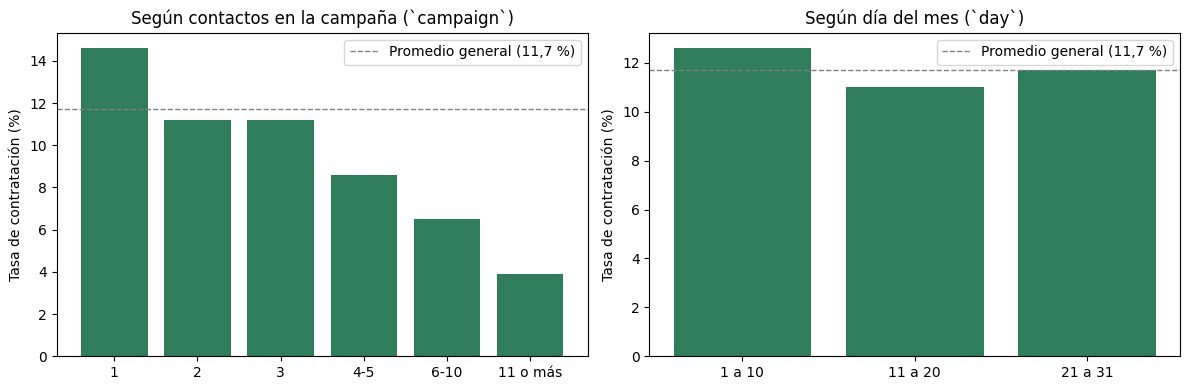

In [30]:
import matplotlib.pyplot as plt


def tasa_contratacion(datos, agrupador):
    """Cantidad de clientes y porcentaje de contratación por grupo."""
    tabla = datos.assign(contrata=(datos["y"] == "yes")).groupby(agrupador, observed=True)["contrata"].agg(["size", "mean"])
    tabla["mean"] = (tabla["mean"] * 100).round(1)
    return tabla.rename(columns={"size": "clientes", "mean": "tasa_contratacion_%"})


por_campaign = tasa_contratacion(df, pd.cut(df["campaign"], [0, 1, 2, 3, 5, 10, 100], labels=["1", "2", "3", "4-5", "6-10", "11 o más"]).rename("contactos en la campaña"))
por_dia = tasa_contratacion(df, pd.cut(df["day"], [0, 10, 20, 31], labels=["1 a 10", "11 a 20", "21 a 31"]).rename("día del mes"))

display(por_campaign)
display(por_dia)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for ax, tabla, titulo in [(ejes[0], por_campaign, "Según contactos en la campaña (`campaign`)"),
                          (ejes[1], por_dia, "Según día del mes (`day`)")]:
    ax.bar(tabla.index.astype(str), tabla["tasa_contratacion_%"], color="#2F7D5B")
    ax.axhline(11.7, color="gray", linestyle="--", linewidth=1, label="Promedio general (11,7 %)")
    ax.set_title(titulo)
    ax.set_ylabel("Tasa de contratación (%)")
    ax.legend()
plt.tight_layout()
plt.show()

**Interpretación de `campaign` y `day`:**

La tasa de contratación baja a medida que aumenta el número de contactos: 14,6 % cuando se contactó al cliente una sola vez, 8,6 % con 4 o 5 contactos y 3,9 % con 11 o más. Esto no significa que llamar más veces reduzca la probabilidad de contratar. Una explicación más razonable es la inversa: a los clientes que no muestran interés se los sigue llamando, de modo que el número de contactos es una **consecuencia** de cómo va la campaña y no algo que el banco sepa antes de llamar por primera vez.

La variable `day` casi no se relaciona con la contratación (entre 11,0 % y 12,6 % según el tramo del mes) y, al igual que `campaign`, describe el último contacto realizado.

Por estos motivos se confirma la decisión de excluir ambas variables: no están disponibles en el momento de la decisión y, en el caso de `campaign`, su relación con la contratación mezcla causa y consecuencia.

### 2.11 Las variables que se mantienen con una salvedad: `month` y `contact`

month,jan,feb,mar,apr,may,jun,jul,aug,sep,oct,nov,dec
clientes,1403.0,2649.0,477.0,2932.0,13766.0,5341.0,6895.0,6247.0,579.0,738.0,3970.0,214.0
tasa_contratacion_%,10.1,16.6,52.0,19.7,6.7,10.2,9.1,11.0,46.5,43.8,10.2,46.7


,clientes,tasa_contratacion_%,% de los clientes
contact,,,
cellular,29285,14.9,64.8
telephone,2906,13.4,6.4
unknown,13020,4.1,28.8


Clientes con medio de contacto desconocido por mes:


month,jan,feb,mar,apr,may,jun,jul,aug,sep,oct,nov,dec
clientes,9,13,7,6,7975,4532,276,51,47,50,51,3


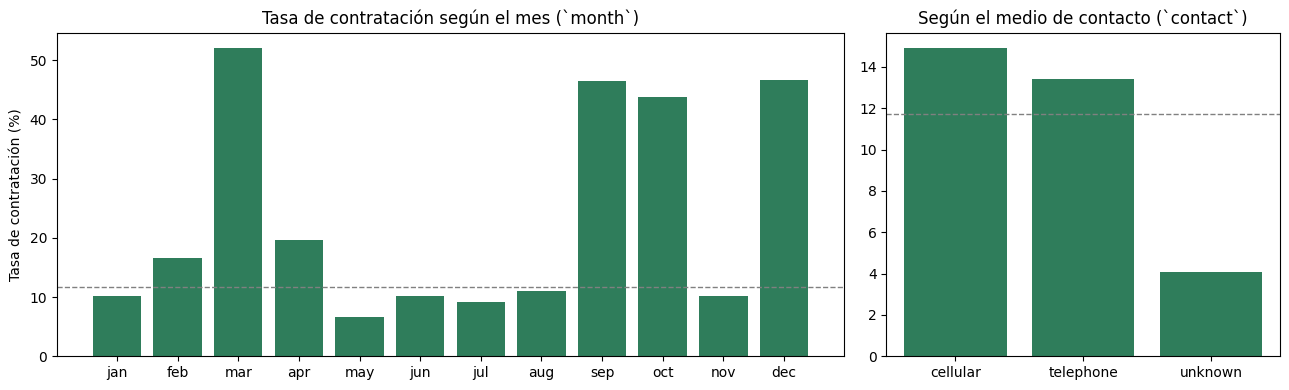

In [31]:
orden_meses = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

por_mes = tasa_contratacion(df, "month").reindex(orden_meses)
por_medio = tasa_contratacion(df, "contact")
por_medio["% de los clientes"] = (por_medio["clientes"] / len(df) * 100).round(1)

# ¿En qué meses se concentran los registros con medio de contacto desconocido?
medio_desconocido_por_mes = (
    df[df["contact"] == "unknown"]["month"].value_counts().reindex(orden_meses).fillna(0).astype(int)
)

display(por_mes.T)
display(por_medio)
print("Clientes con medio de contacto desconocido por mes:")
display(medio_desconocido_por_mes.to_frame("clientes").T)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [2, 1]})
ejes[0].bar(por_mes.index, por_mes["tasa_contratacion_%"], color="#2F7D5B")
ejes[0].axhline(11.7, color="gray", linestyle="--", linewidth=1)
ejes[0].set_title("Tasa de contratación según el mes (`month`)")
ejes[0].set_ylabel("Tasa de contratación (%)")
ejes[1].bar(por_medio.index, por_medio["tasa_contratacion_%"], color="#2F7D5B")
ejes[1].axhline(11.7, color="gray", linestyle="--", linewidth=1)
ejes[1].set_title("Según el medio de contacto (`contact`)")
plt.tight_layout()
plt.show()

**Interpretación de `month` y `contact`:**

- **`month`:** marzo, septiembre, octubre y diciembre tienen tasas muy altas (entre 44 % y 52 %), pero con pocos clientes (477, 579, 738 y 214). Mayo, en cambio, concentra 13.766 clientes y una tasa de 6,7 %. El mes refleja cuándo y cómo se organizó la campaña, no solo el comportamiento de los clientes.
- **`contact`:** el medio `unknown` agrupa 13.020 clientes (28,8 % del total) y solo contrata el 4,1 %, frente a 14,9 % del celular. Además, el 96 % de esos registros corresponde a mayo y junio, lo que sugiere que se trata de un problema de registro de esos meses y no de un medio de contacto real.

Ambas variables las decide el banco al planificar la campaña, por lo que se conocen antes de llamar y se mantienen. La salvedad es que su aporte puede deberse a cómo se organizó esta campaña en particular y no a una característica de los clientes. Para dimensionarlo, en la sección 3.5 se mide cuánto mejora el modelo con ellas y sin ellas.

## Fase 3 (iteración 2): Preparación de los datos

### 3.4 Selección de variables

Se mantiene exactamente la misma división de la iteración 1: a `X_train` y `X_test` solo se les quitan las columnas `day` y `campaign`, de modo que los registros de entrenamiento y de prueba son los mismos y los resultados son comparables. El preprocesamiento (`StandardScaler` para las numéricas y `OneHotEncoder` para las categóricas) es el mismo de la iteración 1, ajustado únicamente con los datos de entrenamiento.

In [32]:
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Mismos registros que la iteración 1, sin las variables que no se conocen antes de llamar
X_train_it2 = X_train.drop(columns=variables_excluidas_it2)
X_test_it2 = X_test.drop(columns=variables_excluidas_it2)
columnas_it2 = X_train_it2.columns.tolist()

# 2. Variables numéricas y categóricas
columnas_numericas_it2 = X_train_it2.select_dtypes(include=["int64", "float64"]).columns.tolist()
columnas_categoricas_it2 = [c for c in columnas_it2 if c not in columnas_numericas_it2]

# 3. Mismo preprocesador de la iteración 1, con las columnas de esta iteración
preprocesador_it2 = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), columnas_numericas_it2),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), columnas_categoricas_it2),
    ]
)


def crear_pipeline_it2(modelo):
    """Pipeline de la iteración 2: preprocesador + modelo, sobre las 13 variables."""
    return Pipeline([
        ("prep", preprocesador_it2),
        ("modelo", modelo),
    ])


# Verificaciones: misma división que la iteración 1 y solo 13 variables
assert X_train_it2.index.equals(X_train.index) and X_test_it2.index.equals(X_test.index)
assert len(columnas_it2) == 13 and not set(variables_excluidas_it2) & set(columnas_it2)
assert len(columnas_numericas_it2) == 4 and len(columnas_categoricas_it2) == 9
assert X_train_it2.isnull().sum().sum() == 0 and X_test_it2.isnull().sum().sum() == 0

print("Variables de la iteración 2 (13):", columnas_it2)
print("Numéricas (4):", columnas_numericas_it2)
print("Categóricas (9):", columnas_categoricas_it2)
print("Registros de entrenamiento / prueba:", len(X_train_it2), "/", len(X_test_it2))
print("Columnas tras el preprocesamiento:", preprocesador_it2.fit_transform(X_train_it2).shape[1],
      "(iteración 1:", preprocesador.fit_transform(X_train).shape[1], ")")

Variables de la iteración 2 (13): ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'month', 'pdays', 'previous', 'poutcome']
Numéricas (4): ['age', 'balance', 'pdays', 'previous']
Categóricas (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Registros de entrenamiento / prueba: 36168 / 9043


Columnas tras el preprocesamiento: 39 (iteración 1: 41 )


### 3.5 ¿Cuánto aporta cada grupo de variables? Validación cruzada

Antes de entrenar se mide cuánto pesa cada grupo de variables, para saber qué se pierde al quitar `day` y `campaign` y cuánto depende el modelo del plan de la campaña (`month` y `contact`).

Se comparan tres conjuntos de variables con validación cruzada de 5 pliegues **solo sobre los datos de entrenamiento** (el conjunto de prueba no se toca) y tres modelos de referencia con hiperparámetros fijos y `class_weight="balanced"`, de modo que la comparación no dependa de ninguna búsqueda de hiperparámetros. La tabla muestra el F1-score promedio de los 5 pliegues junto con su desviación estándar: si una diferencia es menor que la desviación, no se puede distinguir del azar.

In [33]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate

cv_5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

modelos_referencia = {
    "Árbol de Decisión": DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, class_weight="balanced", random_state=42),
    "Regresión Logística": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, class_weight="balanced", random_state=42),
}


def pipeline_por_tipo(modelo):
    """Mismo preprocesamiento de la iteración 1, eligiendo las columnas por su tipo (sirve para cualquier conjunto)."""
    return Pipeline([
        ("prep", ColumnTransformer([
            ("num", StandardScaler(), make_column_selector(dtype_include=np.number)),
            ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), make_column_selector(dtype_exclude=np.number)),
        ])),
        ("modelo", modelo),
    ])


conjuntos = {
    "A. Las 15 variables (iteración 1)": X_train,
    "B. 13 variables: sin day ni campaign (iteración 2)": X_train.drop(columns=["day", "campaign"]),
    "C. 11 variables: además sin month ni contact": X_train.drop(columns=["day", "campaign", "month", "contact"]),
}

filas = []
for nombre_conjunto, X_conjunto in conjuntos.items():
    fila = {"Conjunto de variables": nombre_conjunto}
    for nombre_modelo, modelo in modelos_referencia.items():
        r = cross_validate(pipeline_por_tipo(clone(modelo)), X_conjunto, y_train, cv=cv_5, scoring="f1", n_jobs=-1)
        fila[nombre_modelo] = f"{r['test_score'].mean():.3f} ± {r['test_score'].std():.3f}"
    filas.append(fila)

display(pd.DataFrame(filas).set_index("Conjunto de variables"))

,Árbol de Decisión,Regresión Logística,Random Forest
Conjunto de variables,,,
A. Las 15 variables (iteración 1),0.414 ± 0.024,0.373 ± 0.003,0.437 ± 0.010
B. 13 variables: sin day ni campaign (iteración 2),0.417 ± 0.012,0.372 ± 0.007,0.430 ± 0.012
C. 11 variables: además sin month ni contact,0.351 ± 0.005,0.324 ± 0.007,0.379 ± 0.004


**Interpretación de la validación cruzada:**

- **Quitar `day` y `campaign` casi no cambia el resultado.** El F1 pasa de 0,414 a 0,417 en el Árbol de Decisión, de 0,373 a 0,372 en la Regresión Logística y de 0,437 a 0,430 en el Random Forest. Las diferencias son menores o similares a la desviación entre pliegues (entre 0,003 y 0,024), por lo que no se pueden distinguir del azar. Dicho de otro modo, esas dos variables no aportaban información útil y excluirlas no cuesta desempeño.
- **Quitar además `month` y `contact` sí empeora el resultado de forma clara.** El F1 baja a 0,351 en el árbol, 0,324 en la regresión logística y 0,379 en el bosque, es decir, entre 0,05 y 0,07 menos que con 13 variables, una diferencia mucho mayor que la desviación entre pliegues (hasta 0,012). El plan de la campaña aporta información real.
- **Con solo el perfil del cliente y su historial (11 variables) el modelo predice poco:** el mejor F1 es 0,379. Esa información permite separar solo en parte a quienes contratan de quienes no.

**Decisión:** se trabaja con las 13 variables, que son todas las que se conocen antes de llamar. Hay que tener presente que parte del aporte de `month` y `contact` puede deberse a cómo se organizó esta campaña (sección 2.11).

## Fase 4 (iteración 2): Modelamiento

Se entrenan los mismos tres algoritmos sobre las 13 variables: primero con sus hiperparámetros por defecto (modelo base) y luego optimizados con `GridSearchCV`, usando **las mismas grillas** de la iteración 1 (`param_grid`, `param_grid_lr` y `param_grid_rf`), la misma métrica de optimización (F1-score) y la misma validación cruzada de 5 pliegues.

Mantener las grillas permite aislar el efecto del cambio de variables: si los resultados cambian, no se debe a que se buscó con más o menos libertad.

In [34]:
import time
from sklearn.model_selection import GridSearchCV


def hiperparametros(busqueda):
    """Mejores hiperparámetros sin el prefijo del pipeline y con tipos nativos de Python."""
    limpios = {}
    for nombre, valor in busqueda.best_params_.items():
        valor = valor.item() if hasattr(valor, "item") else valor
        limpios[nombre.replace("modelo__", "")] = round(valor, 4) if isinstance(valor, float) else valor
    return limpios


# Para cada algoritmo: (modelo, grilla de la iteración 1)
configuracion_it2 = {
    "Árbol de Decisión": (DecisionTreeClassifier(random_state=42), param_grid),
    "Regresión Logística": (LogisticRegression(random_state=42, max_iter=1000), param_grid_lr),
    "Random Forest": (RandomForestClassifier(random_state=42), param_grid_rf),
}

resultados_it2 = {}
for nombre, (modelo, grilla) in configuracion_it2.items():
    base = crear_pipeline_it2(clone(modelo)).fit(X_train_it2, y_train)

    busqueda = GridSearchCV(
        estimator=crear_pipeline_it2(clone(modelo)),
        param_grid=grilla,
        scoring="f1",
        cv=5,
        n_jobs=-1,
        return_train_score=True,
    )
    inicio = time.time()
    busqueda.fit(X_train_it2, y_train)
    tiempo = time.time() - inicio

    resultados_it2[nombre] = {"base": base, "optimizado": busqueda.best_estimator_, "busqueda": busqueda}

    print(f"--- {nombre} ---")
    print("Mejores hiperparámetros:", hiperparametros(busqueda))
    print("F1 en CV              :", round(busqueda.best_score_, 4))
    print("F1 en prueba (base)   :", round(f1_score(y_test, base.predict(X_test_it2)), 4))
    print("F1 en prueba (optim.) :", round(f1_score(y_test, busqueda.best_estimator_.predict(X_test_it2)), 4))
    print("Tiempo de búsqueda    :", round(tiempo), "segundos\n")

--- Árbol de Decisión ---
Mejores hiperparámetros: {'class_weight': 'balanced', 'max_depth': 8, 'min_samples_leaf': 5, 'min_samples_split': 2}
F1 en CV              : 0.4157
F1 en prueba (base)   : 0.3168
F1 en prueba (optim.) : 0.4265
Tiempo de búsqueda    : 114 segundos



--- Regresión Logística ---
Mejores hiperparámetros: {'C': 10.0, 'class_weight': 'balanced', 'solver': 'saga'}
F1 en CV              : 0.3762
F1 en prueba (base)   : 0.28
F1 en prueba (optim.) : 0.3776
Tiempo de búsqueda    : 106 segundos



--- Random Forest ---
Mejores hiperparámetros: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
F1 en CV              : 0.4327
F1 en prueba (base)   : 0.3433


F1 en prueba (optim.) : 0.4263
Tiempo de búsqueda    : 473 segundos



## Fase 5 (iteración 2): Evaluación

Se comparan los modelos optimizados de la iteración 2 con los de la iteración 1 sobre el mismo conjunto de prueba (9.043 registros que no participaron en el entrenamiento). La diferencia entre ambas iteraciones es solo el conjunto de variables: 15 en la iteración 1 y 13 en la iteración 2.

,Iteración,Modelo,Accuracy,Precision,Recall,F1 (prueba),F1 (CV),FP,FN,VP
0,Iteración 1,Random Forest,0.8227,0.3512,0.6078,0.4451,0.4396,1188,415,643
1,Iteración 2,Random Forest,0.8154,0.3350,0.5860,0.4263,0.4327,1231,438,620
2,Iteración 1,Regresión Logística,0.7588,0.2700,0.6229,0.3767,0.3754,1782,399,659
3,Iteración 2,Regresión Logística,0.7678,0.2750,0.6021,0.3776,0.3762,1679,421,637
4,Iteración 1,Árbol de Decisión,0.8325,0.3606,0.5586,0.4383,0.4228,1048,467,591
5,Iteración 2,Árbol de Decisión,0.8284,0.3501,0.5454,0.4265,0.4157,1071,481,577


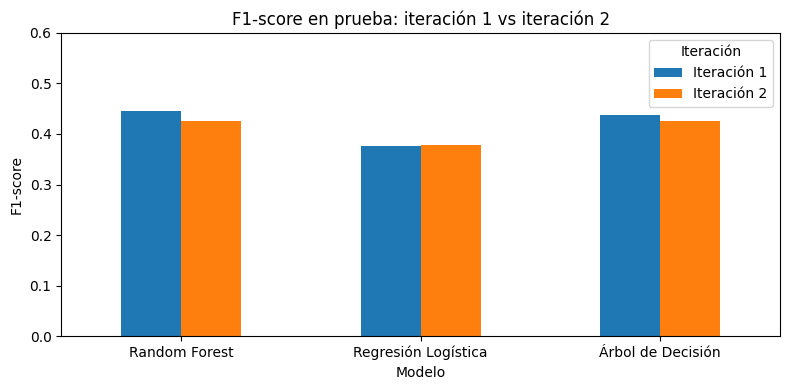

In [35]:
from sklearn.metrics import precision_score, recall_score, confusion_matrix

# Resultados de la iteración 1 con el mismo formato que los de la iteración 2
resultados_it1 = {
    "Árbol de Decisión": {"optimizado": mejor_arbol, "busqueda": grid_search},
    "Regresión Logística": {"optimizado": mejor_lr, "busqueda": grid_search_lr},
    "Random Forest": {"optimizado": mejor_rf, "busqueda": grid_search_rf},
}


def tabla_resultados(resultados, nombre_iteracion, X_prueba):
    """Métricas en prueba (clase 1) de los modelos optimizados de una iteración."""
    filas = []
    for nombre, r in resultados.items():
        pred = r["optimizado"].predict(X_prueba)
        vn, fp, fn, vp = confusion_matrix(y_test, pred).ravel()
        filas.append({
            "Iteración": nombre_iteracion,
            "Modelo": nombre,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred),
            "F1 (prueba)": f1_score(y_test, pred),
            "F1 (CV)": r["busqueda"].best_score_,
            "FP": fp, "FN": fn, "VP": vp,
        })
    return pd.DataFrame(filas)


comparacion_it2 = pd.concat([
    tabla_resultados(resultados_it1, "Iteración 1", X_test),
    tabla_resultados(resultados_it2, "Iteración 2", X_test_it2),
], ignore_index=True).sort_values(["Modelo", "Iteración"], ignore_index=True)
display(comparacion_it2.round(4))

comparacion_it2.pivot(index="Modelo", columns="Iteración", values="F1 (prueba)").plot(kind="bar", figsize=(8, 4))
plt.title("F1-score en prueba: iteración 1 vs iteración 2")
plt.ylabel("F1-score")
plt.ylim(0, 0.6)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretación de los resultados de la iteración 2:**

Al usar solo variables conocidas antes de llamar, el desempeño baja poco. En la prueba, el F1 del Random Forest pasa de 0,4451 a 0,4263 y el del Árbol de Decisión de 0,4383 a 0,4265, mientras que el de la Regresión Logística se mantiene (0,3767 y 0,3776). En validación cruzada las bajas son menores (de 0,4396 a 0,4327 en el bosque y de 0,4228 a 0,4157 en el árbol), lo que es coherente con la sección 3.5: `day` y `campaign` aportaban poco. La pérdida es pequeña y de un tamaño comparable a la variación entre pliegues.

En términos de negocio, el Random Forest de la iteración 2 identifica a 620 de los 1.058 clientes que contratan en la prueba (Recall de 0,59) y, de cada 100 clientes que el modelo sugiere llamar, unos 33 contratan (Precision de 0,335). Si se llamara a clientes al azar solo contrataría el 11,7 %, así que el modelo concentra casi tres veces más contrataciones por llamada. Frente a la iteración 1, detecta 23 clientes interesados menos (los falsos negativos pasan de 415 a 438) y genera 43 llamadas infructuosas más (los falsos positivos pasan de 1.188 a 1.231).

En los tres algoritmos la búsqueda volvió a elegir `class_weight='balanced'`.

El Random Forest sigue siendo el modelo elegido: empata con el árbol en el F1 de prueba (0,4263 y 0,4265), pero lo supera en validación cruzada (0,4327 frente a 0,4157), que es el criterio con el que se elige el modelo de cada iteración en la Fase 6.

### 5.7 ¿Qué variables pesan más en la iteración 2?

Se revisa qué variables usa más el Random Forest de la iteración 2. Como el `OneHotEncoder` convierte cada categoría en una columna, las importancias se suman por variable original para poder interpretarlas.

,Variable,Grupo,Importancia (%)
0,poutcome,Historial de campañas anteriores,18.0
1,month,Plan de la campaña,17.0
2,contact,Plan de la campaña,13.1
3,age,Perfil del cliente,9.1
4,housing,Perfil del cliente,9.1
5,balance,Perfil del cliente,8.2
6,pdays,Historial de campañas anteriores,8.0
7,job,Perfil del cliente,5.1
8,previous,Historial de campañas anteriores,4.9
9,marital,Perfil del cliente,3.8


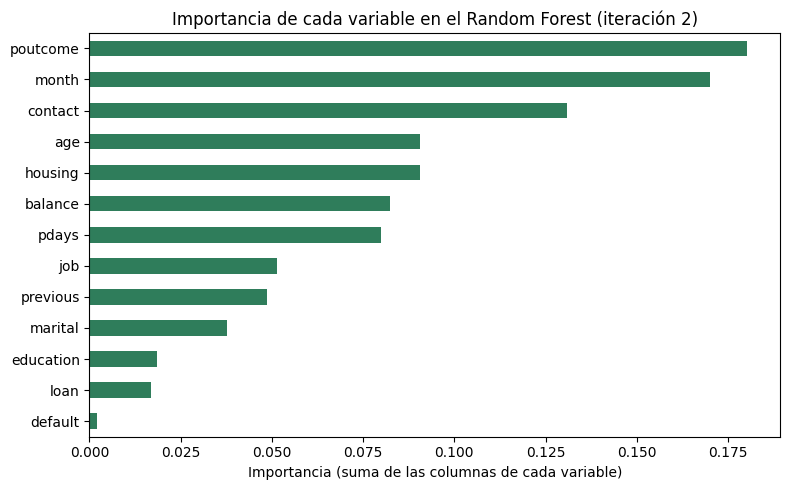

Importancia por grupo (%):


,Importancia (%)
Grupo,
Perfil del cliente,39.1
Historial de campañas anteriores,30.9
Plan de la campaña,30.1


In [36]:
rf_it2 = resultados_it2["Random Forest"]["optimizado"]
nombres_transformados = rf_it2.named_steps["prep"].get_feature_names_out()
importancias = pd.Series(rf_it2.named_steps["modelo"].feature_importances_, index=nombres_transformados)


def variable_original(nombre_columna):
    """'cat__job_admin.' -> 'job';  'num__age' -> 'age'."""
    nombre = nombre_columna.split("__", 1)[1]
    for columna in columnas_categoricas_it2:
        if nombre.startswith(columna + "_"):
            return columna
    return nombre


importancia_variables = importancias.groupby(variable_original).sum().sort_values(ascending=False)
assert abs(importancia_variables.sum() - 1) < 1e-9 and set(importancia_variables.index) == set(columnas_it2)

grupo_de = {v: g for g, lista in grupos_variables.items() for v in lista}
tabla_importancia = pd.DataFrame({
    "Variable": importancia_variables.index,
    "Grupo": [grupo_de[v] for v in importancia_variables.index],
    "Importancia (%)": (importancia_variables.values * 100).round(1),
})
display(tabla_importancia)

importancia_variables.sort_values().plot(kind="barh", figsize=(8, 5), color="#2F7D5B")
plt.title("Importancia de cada variable en el Random Forest (iteración 2)")
plt.xlabel("Importancia (suma de las columnas de cada variable)")
plt.tight_layout()
plt.show()

print("Importancia por grupo (%):")
display((tabla_importancia.groupby("Grupo")["Importancia (%)"].sum().sort_values(ascending=False)).round(1).to_frame())

**Interpretación de la importancia de las variables:**

Las tres variables que más pesan en el Random Forest son `poutcome` (18,0 %), `month` (17,0 %) y `contact` (13,1 %): dos del plan de la campaña y una del historial de campañas anteriores. Después aparecen `age`, `housing` y `balance` (entre 8 % y 9 %), que describen al cliente. Por grupos, el perfil del cliente (8 variables) suma 39,1 %, el historial de campañas anteriores (3 variables) suma 30,9 % y el plan de la campaña (2 variables) suma 30,1 %: con solo 3 y 2 variables, estos dos grupos explican en conjunto más que las ocho del perfil.

Esto confirma lo visto en la sección 3.5: gran parte de la capacidad del modelo no viene de quién es el cliente sino de lo que ocurrió en campañas anteriores y de cuándo y cómo se contacta. Por eso conviene interpretar con cuidado `month` y `contact`, que dependen de cómo se organizó la campaña.

En el otro extremo, `default` (0,2 %), `loan` (1,7 %) y `education` (1,9 %) casi no aportan. Quitarlas es una opción para una iteración de selección de variables. Esta medida es una guía y no una cifra exacta: las importancias del Random Forest tienden a favorecer a las variables con muchos valores distintos.

### 5.8 Cierre de la iteración 2: a qué punto se volvió y a qué conclusión se llegó

**Punto al que se volvió.** Después de evaluar la iteración 1 (Fase 5) se retomó la Fase 1, porque el resultado no bastaba para saber si el modelo sirve en su uso real: decidir a quién llamar *antes* de la llamada. Desde ahí se recorrieron de nuevo las fases 2, 3, 4 y 5, cambiando solo el conjunto de variables.

**Qué se descubrió en cada fase.**

| Fase | Hallazgo |
| :--- | :--- |
| 1. Comprensión del negocio | El modelo debe predecir antes de la llamada: `day` y `campaign` (además de `duration`) no se conocen en ese momento. |
| 2. Comprensión de los datos | `campaign` mezcla causa y consecuencia (a quienes no se interesan se los sigue llamando); `day` casi no se relaciona con la contratación; `contact = unknown` es sobre todo un problema de registro de mayo y junio. |
| 3. Preparación de los datos | Quitar `day` y `campaign` no cambia el F1 en validación cruzada; quitar además `month` y `contact` lo baja entre 0,05 y 0,07. |
| 4. Modelamiento | Con las mismas grillas, los tres algoritmos eligen de nuevo `class_weight='balanced'`. |
| 5. Evaluación | El F1 en prueba baja poco (Random Forest: de 0,4451 a 0,4263) y el modelo detecta 620 de 1.058 contrataciones con una precisión de 0,335. |

**Conclusiones.**

1. Un modelo que usa solo información disponible antes de llamar rinde casi igual que el de la iteración 1. La diferencia es que sus cifras se pueden esperar en el uso real, algo que no se podía asegurar con `day` y `campaign`.
2. El modelo concentra casi tres veces más contrataciones por llamada que llamar al azar (33,5 % frente a 11,7 %), pero deja sin detectar a cerca de 4 de cada 10 clientes interesados (Recall de 0,59) y 2 de cada 3 llamadas sugeridas no terminan en contratación.
3. Gran parte de la capacidad del modelo viene del historial de campañas anteriores y del plan de la campaña (`month` y `contact`), no del perfil del cliente. Esas dos últimas variables reflejan en parte cómo se organizó esta campaña, por lo que hay que ser prudente al extrapolar a campañas futuras.

**Qué sigue.** Los pasos propuestos en la sección 5.6 (ajuste del umbral de decisión y modelos de *boosting*) siguen pendientes, así como una iteración de selección de variables (`default`, `loan` y `education` casi no pesan).

# Fase 6: Despliegue

En esta fase se dejan disponibles las iteraciones en una aplicación **Streamlit** (carpeta `app/`).

Para que la aplicación use exactamente lo que se entrenó aquí, el notebook exporta:

- Los tres modelos optimizados de cada iteración (`Pipeline` completo: preprocesador + algoritmo), de modo que el preprocesamiento en predicción es **el mismo** que en entrenamiento.
- Las métricas de cada iteración (modelos base y optimizados) y la lista de variables que usa cada una (15 en la iteración 1 y 13 en la iteración 2).
- El esquema de variables (columnas, rangos y categorías) con el que se arma el formulario.
- Los datos de generalización: el 20 % de prueba, que no participó ni en el entrenamiento ni en la validación cruzada.

Primero se exporta la iteración 1 (secciones 6.1 a 6.4) y luego la iteración 2 (secciones 6.5 y 6.6).

### 6.1 Exportación de modelos

In [37]:
import json
import joblib
from pathlib import Path

DIR_APP = Path("app")
DIR_MODELOS = DIR_APP / "models"
DIR_DATOS = DIR_APP / "data"
DIR_MODELOS.mkdir(parents=True, exist_ok=True)
DIR_DATOS.mkdir(parents=True, exist_ok=True)

ITERACION = "Iteración 1"
SUFIJO = "iter1"

# Cada entrada: nombre visible -> (clave de archivo, modelo base, modelo optimizado, GridSearchCV)
modelos_iter1 = {
    "Árbol de Decisión":   ("arbol_decision",      modelo_base_clf, mejor_arbol, grid_search),
    "Regresión Logística": ("regresion_logistica", modelo_base_lr,  mejor_lr,    grid_search_lr),
    "Random Forest":       ("random_forest",       modelo_base_rf,  mejor_rf,    grid_search_rf),
}

# Se exportan los modelos optimizados (Pipeline completo con su preprocesador)
for nombre, (clave, _, optimizado, _) in modelos_iter1.items():
    ruta = DIR_MODELOS / f"{clave}_{SUFIJO}.joblib"
    joblib.dump(optimizado, ruta, compress=3)
    print(f"{nombre:<22} -> {ruta}  ({ruta.stat().st_size / 1024:.0f} KB)")

Árbol de Decisión      -> app\models\arbol_decision_iter1.joblib  (10 KB)
Regresión Logística    -> app\models\regresion_logistica_iter1.joblib  (2 KB)
Random Forest          -> app\models\random_forest_iter1.joblib  (1796 KB)


### 6.2 Consolidado de métricas de la iteración

Se calculan las mismas métricas para los modelos base y optimizados sobre el conjunto de prueba, y se guardan para mostrarlas en la aplicación.

In [38]:
from sklearn.metrics import precision_score, recall_score, confusion_matrix

def calcular_metricas(modelo, X, y_real):
    """Métricas de la clase 1 (cliente que contrata) sobre un conjunto dado."""
    pred = modelo.predict(X)
    vn, fp, fn, vp = confusion_matrix(y_real, pred).ravel()
    return {
        "accuracy": float(accuracy_score(y_real, pred)),
        "precision": float(precision_score(y_real, pred)),
        "recall": float(recall_score(y_real, pred)),
        "f1": float(f1_score(y_real, pred)),
        "vn": int(vn), "fp": int(fp), "fn": int(fn), "vp": int(vp),
    }

metricas_iter1 = {
    "iteracion": ITERACION,
    "n_test": int(len(X_test)),
    "variables": X_train.columns.tolist(),
    "modelos": {},
}

filas = []
for nombre, (clave, base, optimizado, grid) in modelos_iter1.items():
    m_base = calcular_metricas(base, X_test, y_test)
    m_opt = calcular_metricas(optimizado, X_test, y_test)
    metricas_iter1["modelos"][nombre] = {
        "base": m_base,
        "optimizado": m_opt,
        "hiperparametros": {k.replace("modelo__", ""): v for k, v in grid.best_params_.items()},
        "f1_cv": float(grid.best_score_),
    }
    filas.append({"Modelo": nombre, "Versión": "Base", **m_base})
    filas.append({"Modelo": nombre, "Versión": "Optimizado", **m_opt})

# El modelo seleccionado es el de mayor F1 en validación cruzada (no se elige con los datos de prueba)
metricas_iter1["mejor_modelo"] = max(metricas_iter1["modelos"], key=lambda n: metricas_iter1["modelos"][n]["f1_cv"])

with open(DIR_MODELOS / f"metricas_{SUFIJO}.json", "w", encoding="utf-8") as f:
    json.dump(metricas_iter1, f, ensure_ascii=False, indent=2, default=str)

df_metricas = pd.DataFrame(filas)
display(df_metricas.round(4))
print("Modelo con mayor F1 en validación cruzada:", metricas_iter1["mejor_modelo"])

,Modelo,Versión,accuracy,precision,recall,f1,vn,fp,fn,vp
0,Árbol de Decisión,Base,0.8304,0.2976,0.3308,0.3133,7159,826,708,350
1,Árbol de Decisión,Optimizado,0.8325,0.3606,0.5586,0.4383,6937,1048,467,591
2,Regresión Logística,Base,0.8933,0.6655,0.1767,0.2793,7891,94,871,187
3,Regresión Logística,Optimizado,0.7588,0.2700,0.6229,0.3767,6203,1782,399,659
4,Random Forest,Base,0.8944,0.6373,0.2259,0.3336,7849,136,819,239
5,Random Forest,Optimizado,0.8227,0.3512,0.6078,0.4451,6797,1188,415,643


Modelo con mayor F1 en validación cruzada: Random Forest


### 6.3 Esquema de variables y datos de generalización

El esquema guarda el orden de las 15 columnas predictoras, los rangos de las numéricas y las categorías válidas, de modo que el formulario de la aplicación se construye a partir de lo que realmente vio el modelo.

Los datos de generalización son el conjunto de prueba (`X_test`, `y_test`): registros que los modelos **no vieron** durante el entrenamiento ni durante la búsqueda de hiperparámetros.

In [39]:
esquema = {
    "columnas": X_train.columns.tolist(),
    "numericas": {
        col: {
            "min": int(df[col].min()),
            "max": int(df[col].max()),
            "mediana": int(df[col].median()),
        }
        for col in columnas_numericas
    },
    "categoricas": {
        col: {
            "categorias": sorted(X_train[col].unique().tolist()),
            "moda": X_train[col].mode()[0],
        }
        for col in columnas_categoricas
    },
    "excluidas": ["duration"],
    "objetivo": "y",
}

with open(DIR_MODELOS / "esquema.json", "w", encoding="utf-8") as f:
    json.dump(esquema, f, ensure_ascii=False, indent=2)

# Datos de generalización: X_test con su etiqueta real original ("yes"/"no")
generalizacion = X_test.copy()
generalizacion["y"] = df.loc[X_test.index, "y"]
generalizacion.to_csv(DIR_DATOS / f"generalizacion_{SUFIJO}.csv", index=False)

print("Columnas del esquema:", len(esquema["columnas"]))
print("Registros de generalización:", len(generalizacion))
print(generalizacion["y"].value_counts(normalize=True).round(3).to_dict())

Columnas del esquema: 15
Registros de generalización: 9043
{'no': 0.883, 'yes': 0.117}


### 6.4 Verificación de consistencia entrenamiento / predicción

Se cargan los modelos desde disco, tal como lo hará la aplicación, y se comprueba que sus predicciones sobre el conjunto de prueba son **idénticas** a las obtenidas en este notebook. Esto confirma que el preprocesamiento aplicado al predecir es el mismo que el usado al entrenar.

In [40]:
import numpy as np

predicciones_notebook = {
    "Árbol de Decisión": pred_grid,
    "Regresión Logística": pred_grid_lr,
    "Random Forest": pred_grid_rf,
}

for nombre, (clave, _, _, _) in modelos_iter1.items():
    cargado = joblib.load(DIR_MODELOS / f"{clave}_{SUFIJO}.joblib")

    # La app lee el CSV exportado: se predice desde ese archivo para probar todo el circuito
    datos_csv = pd.read_csv(DIR_DATOS / f"generalizacion_{SUFIJO}.csv")
    pred_desde_disco = cargado.predict(datos_csv[esquema["columnas"]])
    proba = cargado.predict_proba(datos_csv[esquema["columnas"]])[:, 1]

    assert np.array_equal(pred_desde_disco, predicciones_notebook[nombre]), f"Predicciones distintas en {nombre}"
    assert ((proba >= 0) & (proba <= 1)).all()
    print(f"OK  {nombre:<22} predicciones idénticas al notebook ({len(pred_desde_disco)} registros)")

OK  Árbol de Decisión      predicciones idénticas al notebook (9043 registros)
OK  Regresión Logística    predicciones idénticas al notebook (9043 registros)


OK  Random Forest          predicciones idénticas al notebook (9043 registros)


### 6.5 Exportación de la iteración 2

Se exporta la iteración 2 con el mismo formato de la iteración 1 (un archivo `.joblib` por modelo y un JSON de métricas). El JSON incluye la lista de las 13 variables que usa esta iteración, de modo que la aplicación solo pide esos datos en el formulario y selecciona esas columnas al evaluar.

Los datos de generalización son los mismos de la iteración 1: la división de los datos es idéntica en ambas iteraciones, y la aplicación selecciona las 13 columnas que corresponden.

In [41]:
claves_modelos = {
    "Árbol de Decisión": "arbol_decision",
    "Regresión Logística": "regresion_logistica",
    "Random Forest": "random_forest",
}


def exportar_iteracion(nombre_iteracion, sufijo, resultados, columnas, X_prueba):
    metricas = {"iteracion": nombre_iteracion, "n_test": int(len(X_prueba)), "variables": list(columnas), "modelos": {}}
    for nombre, r in resultados.items():
        ruta = DIR_MODELOS / f"{claves_modelos[nombre]}_{sufijo}.joblib"
        joblib.dump(r["optimizado"], ruta, compress=3)
        print(f"{nombre:<22} -> {ruta}  ({ruta.stat().st_size / 1024:.0f} KB)")

        metricas["modelos"][nombre] = {
            "base": calcular_metricas(r["base"], X_prueba, y_test),
            "optimizado": calcular_metricas(r["optimizado"], X_prueba, y_test),
            "hiperparametros": hiperparametros(r["busqueda"]),
            "f1_cv": float(r["busqueda"].best_score_),
        }

    # El modelo seleccionado es el de mayor F1 en validación cruzada (no se elige con los datos de prueba)
    metricas["mejor_modelo"] = max(metricas["modelos"], key=lambda n: metricas["modelos"][n]["f1_cv"])
    with open(DIR_MODELOS / f"metricas_{sufijo}.json", "w", encoding="utf-8") as f:
        json.dump(metricas, f, ensure_ascii=False, indent=2)
    print("Modelo con mayor F1 en validación cruzada:", metricas["mejor_modelo"], "\n")
    return metricas


metricas_iter2 = exportar_iteracion("Iteración 2", "iter2", resultados_it2, columnas_it2, X_test_it2)

Árbol de Decisión      -> app\models\arbol_decision_iter2.joblib  (13 KB)
Regresión Logística    -> app\models\regresion_logistica_iter2.joblib  (2 KB)
Random Forest          -> app\models\random_forest_iter2.joblib  (1779 KB)


Modelo con mayor F1 en validación cruzada: Random Forest 



### 6.6 Verificación de consistencia de la iteración 2

Igual que en la iteración 1, se cargan los modelos desde disco y se comprueba que predicen exactamente lo mismo que en el notebook, usando el archivo de generalización que lee la aplicación y seleccionando las 13 variables de la iteración.

In [42]:
datos_csv = pd.read_csv(DIR_DATOS / "generalizacion_iter1.csv")
assert len(datos_csv) == len(X_test)   # misma división de datos en ambas iteraciones

for nombre, r in resultados_it2.items():
    cargado = joblib.load(DIR_MODELOS / f"{claves_modelos[nombre]}_iter2.joblib")

    pred_desde_disco = cargado.predict(datos_csv[columnas_it2])
    proba = cargado.predict_proba(datos_csv[columnas_it2])[:, 1]

    assert np.array_equal(pred_desde_disco, r["optimizado"].predict(X_test_it2)), f"Predicciones distintas en {nombre}"
    assert ((proba >= 0) & (proba <= 1)).all()
    print(f"OK  iter2  {nombre:<22} predicciones idénticas al notebook ({len(pred_desde_disco)} registros)")

OK  iter2  Árbol de Decisión      predicciones idénticas al notebook (9043 registros)
OK  iter2  Regresión Logística    predicciones idénticas al notebook (9043 registros)


OK  iter2  Random Forest          predicciones idénticas al notebook (9043 registros)


### 6.7 Ejecución de la aplicación

Desde la carpeta del proyecto:

```bash
pip install -r requirements.txt
streamlit run app/app.py
```

**Funcionalidades de la aplicación**

- *Predicción individual:* formulario con los datos de un cliente (solo las variables que usa la iteración elegida) y consulta simultánea a los modelos de esa iteración.
- *Datos de generalización:* evaluación de los modelos sobre registros no vistos (el conjunto de prueba).
- *Desempeño de los modelos:* comparación de Accuracy, Precision, Recall y F1 entre modelos base y optimizados, y entre iteraciones.

**Cómo incorporar nuevas iteraciones:** repetir el bloque de exportación (6.5) con el sufijo `iter3`, `iter4`, etc. (indicando las variables que usa la iteración) y agregar una entrada al diccionario `ITERACIONES` de `app/config.py`. La aplicación recorre ese registro y lee la lista de variables desde el JSON de métricas, por lo que no requiere más cambios. Si una iteración agrega variables nuevas dentro del `Pipeline` (por ejemplo, con una clase propia), esa clase debe guardarse en un módulo dentro de `app/` para que `joblib` pueda cargar el modelo.

### Conclusión

Se desarrollaron dos iteraciones de CRISP-DM sobre el mismo conjunto de datos y la misma división entre entrenamiento y prueba. En ambas, el modelo con mejor F1 en validación cruzada fue el Random Forest optimizado (F1 de 0,4451 en la prueba en la iteración 1 y de 0,4263 en la iteración 2).

La iteración 2 volvió a la Fase 1 para precisar el uso real del modelo (decidir a quién llamar) y excluyó `day` y `campaign`, que no se conocen antes de llamar. El desempeño bajó poco y el modelo resultante puede usarse con la información que el banco realmente tiene antes de la llamada.

Los modelos de ambas iteraciones quedan disponibles en la aplicación, con sus métricas y su evaluación sobre datos que no participaron en el entrenamiento. La iteración 2 pide en el formulario solo las 13 variables que usa.